# 02 — Preprocess the CMU walking segments

Input: the `walking` folder made by notebook 01 (`segments/*.npz` + `walking_segments.csv`).

| Step | What happens |
|---|---|
| **0. Quality check** | **Frames:** missing frames (frame count vs. the source range), empty values (NaN/inf), sudden root jumps, sudden joint-rotation jumps, frozen (repeated) frames, unusual frame rate. **Joints:** all 52 SMPL+H joints present, no empty joint values. Short problems are repaired by interpolation; long ones mean the segment is dropped. Everything goes into `quality_report.csv`. |
| **1. Skeleton** | Runs the SMPL+H body model (forward kinematics) to get 3D positions of the 22 body joints. Then checks the skeleton: no empty joints, constant bone lengths, plausible body height. |
| **2. Floor** | Shifts each segment so the feet touch height 0. |
| **3. Resample** | 120 Hz (or 60 Hz) → 30 Hz. |
| **4. Windows** | Cuts fixed-length windows (default 60 frames = 2 s, 50 % overlap). |
| **5. Facing** | Each window starts at the origin, facing +x. |
| **6. Features** | Per frame: root height, root forward/sideways speed, turning speed, local joint positions, joint velocities, foot contacts. |
| **7. Ablation version** | Same features **without** the root speed (root-centred), for the root-velocity ablation. |
| **7b. Drop non-walking windows** | Windows whose mean forward speed is below `MIN_WINDOW_FWD_SPEED` (standing, turning on the spot) are removed and listed in `dropped_windows.csv`. |
| **8. Split by person** | Train / val / test with no person in two sets. |
| **9. Normalise** | Mean and std from **train only**, applied to all splits. |
| **10. Check** | Rebuilds the skeleton from the features **and** from the saved SMPL+H rotations, measures the error, draws stick figures. |
| **10b. Official model check** | Compares this notebook's forward kinematics with the official SMPL+H code (`smplx` or `human_body_prior`). |
| **11. Visuals** | Root trajectory, pose heatmaps, body shape, speed and joint angles over time, 3D skeleton and animation, dataset overview. |

Besides the features, every window also keeps its **SMPL+H rotations** (`poses`, `trans` at 30 Hz in the same canonical frame), plus `betas` and `gender`, so you can render a mesh or train a rotation-based model later.

Coordinates stay **z-up** (as in AMASS), in metres.

## Settings
Edit the paths here. You need the **SMPL+H body model** (`model.npz` files) from https://mano.is.tue.mpg.de → Downloads → *Extended SMPL+H model*. After unpacking you should have `male/model.npz`, `female/model.npz` (and maybe `neutral/model.npz`).

In [1]:
from pathlib import Path

WALK_DIR       = Path(r"C:\Users\hasna\Documents\Good Practise\CMU\walking")
SEG_DIR        = WALK_DIR / "segments"
SEG_CSV        = WALK_DIR / "walking_segments.csv"
BODY_MODEL_DIR = Path(r"C:\Users\hasna\Documents\Good Practise\smplh")   # folder with male/, female/ (neutral/)
OUT_DIR        = WALK_DIR / "preprocessed"

# Which segments to use (flags come from notebook 01)
KEEP_STYLIZED = True    # sad / drunk / zombie walks...
KEEP_TURNING  = True
KEEP_MIXED    = True

# Step 0: quality check
EXPECTED_FPS        = (60.0, 120.0)  # CMU in AMASS; other rates are flagged (and still resampled)
MAX_ROOT_SPEED      = 5.0     # m/s between two frames; faster = glitch
MAX_JOINT_SPEED_DEG = 1000.0  # deg/s rotation change of any body joint between frames; faster = glitch
MIN_FROZEN_RUN      = 3       # this many identical frames in a row = frozen frames
MAX_GAP_SEC         = 0.10    # longest run of bad frames that is repaired by interpolation
MAX_BAD_FRACTION    = 0.05    # more bad frames than this = drop the segment
HEAD_HEIGHT_RANGE   = (1.2, 2.0)  # m, head joint above the floor (skeleton check)
MAX_BONE_STD_MM     = 1.0     # bone lengths must stay constant

# Steps 3–6
TARGET_FPS     = 30
WINDOW_FRAMES  = 60           # 2 s at 30 Hz
STRIDE_FRAMES  = 30           # 50 % overlap
CONTACT_VEL    = 0.30         # m/s, foot slower than this ...
CONTACT_HEIGHT = {"L_ankle": 0.12, "R_ankle": 0.12, "L_foot": 0.07, "R_foot": 0.07}  # ... and lower than this = contact

# Step 7b: drop windows that are not walking
MIN_WINDOW_FWD_SPEED = 0.3   # m/s, mean forward speed of a window; slower = standing / turning on the spot

# Rotations: also save SMPL+H poses/trans (30 Hz, canonical frame), betas and gender for every window
SAVE_ROTATIONS = True

# Step 10b: compare with the official SMPL+H code (needs `pip install smplx torch` or human_body_prior)
FK_CHECK_SEGMENTS = 3        # how many segments to compare

# Step 11: segment to plot, e.g. "07_04_seg0" (None = first segment)
VIS_SEGMENT = None

# Step 8
SPLIT_RATIOS = (0.70, 0.15, 0.15)   # train, val, test (by number of windows)
SEED         = 42
SAME_PERSON  = []   # CMU sometimes gives one person several subject numbers, e.g. [[7, 8]] keeps 7 and 8 together

In [2]:
import json, warnings, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.signal import savgol_filter
from scipy.spatial.transform import Rotation, Slerp
from tqdm.auto import tqdm

assert SEG_DIR.exists(), f"Not found: {SEG_DIR} (run notebook 01 first)"

# ---- find the SMPL+H body model (male/model.npz, female/model.npz)
def find_body_model_dir():
    search_roots = [BODY_MODEL_DIR, BODY_MODEL_DIR.parent, Path.home() / "Downloads"]
    for root in search_roots:
        if not root.exists():
            continue
        # already unpacked?
        for p in root.rglob("model.npz"):
            if p.parent.name in ("male", "female", "neutral"):
                return p.parent.parent
        # downloaded but not unpacked yet? -> unpack into BODY_MODEL_DIR
        for arc in list(root.glob("*smplh*.tar.xz")) + list(root.glob("*smplh*.tar.bz2")) + list(root.glob("*smplh*.zip")):
            print("unpacking", arc)
            BODY_MODEL_DIR.mkdir(parents=True, exist_ok=True)
            if arc.suffix == ".zip":
                import zipfile; zipfile.ZipFile(arc).extractall(BODY_MODEL_DIR)
            else:
                with tarfile.open(arc) as t:
                    t.extractall(BODY_MODEL_DIR)
            for p in BODY_MODEL_DIR.rglob("model.npz"):
                if p.parent.name in ("male", "female", "neutral"):
                    return p.parent.parent
    return None

found = find_body_model_dir()
if found is None:
    raise FileNotFoundError(
        "SMPL+H body model not found.\n"
        "1. Register at https://mano.is.tue.mpg.de and sign in\n"
        "2. Downloads -> 'Extended SMPL+H model' (file smplh.tar.xz)\n"
        f"3. Put that file in {BODY_MODEL_DIR.parent} or your Downloads folder and re-run this cell\n"
        "   (it is unpacked automatically), or unpack it yourself so you have "
        f"{BODY_MODEL_DIR}\\male\\model.npz")
BODY_MODEL_DIR = found
print("body model folder:", BODY_MODEL_DIR, "->", sorted(p.parent.name for p in BODY_MODEL_DIR.glob("*/model.npz")))
OUT_DIR.mkdir(parents=True, exist_ok=True)

# SMPL body joints (first 22 of SMPL+H)
JOINT_NAMES = ["pelvis", "L_hip", "R_hip", "spine1", "L_knee", "R_knee", "spine2", "L_ankle", "R_ankle", "spine3",
               "L_foot", "R_foot", "neck", "L_collar", "R_collar", "head", "L_shoulder", "R_shoulder",
               "L_elbow", "R_elbow", "L_wrist", "R_wrist"]
J = {n: i for i, n in enumerate(JOINT_NAMES)}
N_BODY, N_ALL = 22, 52
FEET = [J["L_ankle"], J["R_ankle"], J["L_foot"], J["R_foot"]]
FOOT_NAMES = ["L_ankle", "R_ankle", "L_foot", "R_foot"]

segs = pd.read_csv(SEG_CSV)
keep = np.ones(len(segs), bool)
if not KEEP_STYLIZED: keep &= ~segs.stylized
if not KEEP_TURNING:  keep &= ~segs.turning
if not KEEP_MIXED:    keep &= segs.text_category != "mixed"
segs = segs[keep].reset_index(drop=True)
print(len(segs), "segments selected,", segs.subject.nunique(), "subjects")

body model folder: C:\Users\hasna\Documents\Good Practise\smplh -> ['female', 'male', 'neutral']
477 segments selected, 50 subjects


c:\Users\hasna\Documents\fine-tuned-domain-specific-whisper-model\.venv-parakeet\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# =====================================================================
# 📊 Presentation helpers: one style for all slide figures
# Every "For the slides" cell below uses these. Figures are also saved as PNG in OUT_DIR/figures.
# =====================================================================
import re
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
STATUS_COLORS = {"ok": "#0ca30c", "repaired": "#fab219", "dropped": "#d03b3b"}
STATUS_ORDER = ["ok", "repaired", "dropped"]
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SPLIT_COLORS = {"train": SERIES[0], "val": SERIES[1], "test": SERIES[2]}
KIND_COLORS = {"plain walk": SERIES[0], "turning": SERIES[1], "stylised": SERIES[6], "mixed": SERIES[2]}

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def grid(ax, axis="both"):
    ax.grid(axis=axis, color=GRID, lw=0.8); ax.set_axisbelow(True)

def hbar(ax, labels, values, colors, total=None):
    """Horizontal bars with the value (and % of total) written at the end of each bar."""
    values = np.asarray(values)
    y = np.arange(len(labels))[::-1]
    ax.barh(y, values, color=colors, height=0.6, edgecolor="white", linewidth=2)
    ax.set_yticks(y, labels); ax.tick_params(axis="y", length=0, labelcolor=INK)
    grid(ax, "x")
    vmax = values.max() if len(values) and values.max() > 0 else 1
    for yi, v in zip(y, values):
        txt = f"{v:,}" + (f"  ({100 * v / total:.1f}%)" if total else "")
        ax.text(v + vmax * 0.01, yi, txt, va="center", color=INK2, fontsize=11)
    ax.set_xlim(0, vmax * 1.3)

def key_facts(title, *lines):
    """Prints the numbers worth saying out loud on the slide."""
    print("━" * 78 + f"\n  🎤 {title}\n" + "━" * 78)
    for l in lines:
        print("  •", l)
    print()

def clip_kind(df):
    return np.select([df.text_category.eq("mixed"), df.turning.astype(bool), df.stylized.astype(bool)],
                     ["mixed", "turning", "stylised"], "plain walk")

def side_view_draw(ax, P, color, x0=0.0, alpha=1.0, lw=2):
    """Draw one pose (22, 3) from the side: rotated so the body faces +x, plotted as x (forward) vs z (up), shifted by x0."""
    across = (P[J["L_hip"]] - P[J["R_hip"]]) + (P[J["L_shoulder"]] - P[J["R_shoulder"]])
    th = np.arctan2(-across[0], across[1])
    c, s = np.cos(-th), np.sin(-th)
    x = c * (P[:, 0] - P[0, 0]) - s * (P[:, 1] - P[0, 1]) + x0
    for j, p in BONES:
        ax.plot([x[j], x[p]], [P[j, 2], P[p, 2]], color=color, alpha=alpha, lw=lw, solid_capstyle="round")

In [ ]:
# 📊 For the slides — the input data at a glance
kinds = pd.Series(clip_kind(segs)).value_counts().reindex(list(KIND_COLORS), fill_value=0)
per_subj = segs.subject.value_counts()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
ax[0].bar(range(len(per_subj)), per_subj.values, color=SERIES[0], width=0.8)
ax[0].set_xticks(range(len(per_subj)), per_subj.index, fontsize=7, rotation=90)
ax[0].set(title=f"Segments per subject ({len(per_subj)} subjects)", xlabel="subject", ylabel="segments"); grid(ax[0], "y")

hbar(ax[1], kinds.index, kinds.values, [KIND_COLORS[k] for k in kinds.index], total=kinds.sum())
ax[1].set(title="Clip types", xlabel="segments")

if "cadence_spm" in segs and segs.cadence_spm.notna().any():
    cad = segs.cadence_spm.dropna()
    ax[2].hist(cad, bins=30, color=SERIES[2], edgecolor="white")
    ax[2].axvspan(100, 120, color=GRID, alpha=0.6, lw=0, label="typical adult walking\n(~100–120 steps/min)")
    ax[2].set(title="Cadence per segment", xlabel="steps per minute", ylabel="segments"); ax[2].legend(fontsize=9); grid(ax[2], "y")
else:
    ax[2].axis("off")
fig.tight_layout(); save_fig(fig, "00_dataset_overview")

key_facts("Input data",
    f"{len(segs)} walking segments from {segs.subject.nunique()} CMU subjects",
    f"median {per_subj.median():.0f} segments per subject; most: subject {per_subj.index[0]} with {per_subj.iloc[0]}, fewest: {per_subj.min()}",
    *[f"{k}: {v} segments ({100 * v / len(segs):.0f}%)" for k, v in kinds.items() if v],
    *([f"median cadence {segs.cadence_spm.median():.0f} steps/min (range {segs.cadence_spm.min():.0f}–{segs.cadence_spm.max():.0f})"]
      if "cadence_spm" in segs and segs.cadence_spm.notna().any() else []))

### 🎤 Talking points — the input data
**What the slide shows:** how many walking clips we start from, who they come from, and what kind of walking they contain.

**Your numbers (last run):** 477 segments from 50 subjects. All three clip types are kept (`KEEP_STYLIZED`, `KEEP_TURNING`, `KEEP_MIXED` = True).

**Interesting facts:**
- The **CMU Graphics Lab Motion Capture Database** was recorded with a Vicon system and ~41 markers on a suit. It contains more than 2,600 clips from over 100 subjects. Walking is its largest single activity.
- We use the **AMASS** version. AMASS (2019) fitted one body model (SMPL+H) to the marker data of 15+ mocap datasets, so every clip now has the same skeleton, joint rotations and body shape.
- The subjects are not balanced: a few people contribute many clips. This matters later, when we split the data by person (Step 8).
- Healthy adults usually walk at **about 100–120 steps per minute**. Values far outside that are usually slow or stylised walks.

## Step 0 — Frame and joint quality check
For every segment file:

- **Joints:** all 52 SMPL+H joints present (`poses` has 156 numbers per frame); which joints have empty values.
- **Frames:** frame count matches the source range from notebook 01 (otherwise frames are missing); `poses` and `trans` have the same number of frames; frame rate is expected.
- **Bad frames:** empty values, root jumps, joint-rotation jumps, frozen frames.

Bad frames at the very start or end are cut off. Bad frames inside are filled by interpolation (linear for position, spherical for rotations) if the gap is short. Otherwise the segment is dropped.

In [3]:
REQUIRED_KEYS = ["trans", "poses", "betas", "gender"]

def runs(mask):
    # (start, end) of each run of True values
    e = np.flatnonzero(np.diff(np.r_[0, mask.astype(int), 0]))
    return list(zip(e[::2], e[1::2]))

def quality_check(row):
    path = SEG_DIR / f"{row.segment_id}.npz"
    rec = dict(segment_id=row.segment_id, subject=row.subject, status="ok", issues="")
    issues = []
    def drop(msg):
        issues.append(msg); rec.update(status="dropped", issues="; ".join(issues)); return rec, None

    if not path.exists():
        return drop("file missing")
    d = dict(np.load(path, allow_pickle=True))
    missing = [k for k in REQUIRED_KEYS if k not in d]
    if missing:
        return drop(f"missing arrays: {missing}")
    fps = float(d.get("mocap_framerate", d.get("mocap_frame_rate", np.nan)))
    trans, poses, betas = d["trans"].astype(np.float64), d["poses"].astype(np.float64), d["betas"].astype(np.float64)
    T = len(trans)
    rec.update(fps=fps, n_frames=T, n_joints=poses.shape[1] // 3 if poses.ndim == 2 else 0)

    if len(poses) != T:
        return drop(f"missing frames: poses has {len(poses)} frames, trans has {T}")

    # --- joint checks
    if poses.ndim != 2 or poses.shape[1] != N_ALL * 3:
        return drop(f"joints: expected {N_ALL} joints ({N_ALL*3} values), found {poses.shape[-1]} values")
    nan_joints = np.flatnonzero(~np.isfinite(poses.reshape(T, N_ALL, 3)).all(axis=(0, 2)))
    rec["joints_with_empty_values"] = ",".join(str(j) for j in nan_joints)
    if not np.isfinite(betas).all():
        return drop("body shape (betas) has empty values")

    # --- frame checks
    expected = int(row.end_frame - row.start_frame)
    if T != expected:
        return drop(f"missing frames: {T} frames, expected {expected}")
    if not np.isfinite(fps) or fps <= 0:
        return drop("no frame rate")
    if not any(abs(fps - f) < 1e-3 for f in EXPECTED_FPS):
        issues.append(f"unusual frame rate {fps:g}")

    bad = ~np.isfinite(trans).all(1) | ~np.isfinite(poses).all(1)
    rec["empty_frames"] = int(bad.sum())

    tr = np.where(np.isfinite(trans), trans, 0.0)
    root_speed = np.linalg.norm(np.diff(tr, axis=0), axis=1) * fps
    jump = np.r_[False, root_speed > MAX_ROOT_SPEED] & ~bad & ~np.r_[False, bad[:-1]]
    rec["root_jump_frames"] = int(jump.sum())

    rv = np.where(np.isfinite(poses), poses, 0.0)[:, :N_BODY * 3].reshape(T, N_BODY, 3)
    r = Rotation.from_rotvec(rv.reshape(-1, 3))
    rmat = r.as_matrix().reshape(T, N_BODY, 3, 3)
    rel = np.einsum("tjba,tjbc->tjac", rmat[:-1], rmat[1:])           # R_{t-1}^T R_t
    ang = np.degrees(np.arccos(np.clip((np.trace(rel, axis1=2, axis2=3) - 1) / 2, -1, 1))) * fps
    pjump = np.r_[False, (ang > MAX_JOINT_SPEED_DEG).any(1)] & ~bad & ~np.r_[False, bad[:-1]]
    rec["joint_jump_frames"] = int(pjump.sum())

    same = np.r_[False, (poses[1:] == poses[:-1]).all(1) & (trans[1:] == trans[:-1]).all(1)]
    frozen = np.zeros(T, bool)
    for s, e in runs(same):
        if e - s + 1 >= MIN_FROZEN_RUN:
            frozen[s:e] = True
    rec["frozen_frames"] = int(frozen.sum())

    bad |= jump | pjump | frozen

    # cut bad frames at the start/end, repair inside
    good_idx = np.flatnonzero(~bad)
    if len(good_idx) < 2:
        return drop("no usable frames")
    a, b = good_idx[0], good_idx[-1] + 1
    rec.update(trim_start=int(a), trim_end=int(T - b))
    trans, poses, bad = trans[a:b], poses[a:b], bad[a:b]
    T2 = len(trans)
    n_bad = int(bad.sum())
    longest = max((e - s for s, e in runs(bad)), default=0)
    rec.update(bad_frames_inside=n_bad, longest_gap_frames=longest)
    if n_bad / T2 > MAX_BAD_FRACTION:
        return drop(f"{n_bad} bad frames ({100*n_bad/T2:.1f}%)")
    if longest > MAX_GAP_SEC * fps:
        return drop(f"gap of {longest} bad frames ({longest/fps:.2f} s)")

    if n_bad:
        t, g = np.arange(T2), ~bad
        for k in range(3):
            trans[bad, k] = np.interp(t[bad], t[g], trans[g, k])
        rv_all = poses.reshape(T2, N_ALL, 3)
        for j in range(N_ALL):
            rv_all[bad, j] = Slerp(t[g], Rotation.from_rotvec(rv_all[g, j]))(t[bad]).as_rotvec()
        poses = rv_all.reshape(T2, -1)
        issues.append(f"repaired {n_bad} frames")
        rec["status"] = "repaired"
    if a or T - b:
        issues.append(f"trimmed {a}+{T-b} edge frames")
        if rec["status"] == "ok": rec["status"] = "repaired"
    rec["issues"] = "; ".join(issues)
    gender = d["gender"]
    gender = gender.item() if hasattr(gender, "item") else gender
    gender = gender.decode() if isinstance(gender, bytes) else str(gender)
    return rec, dict(trans=trans, poses=poses, betas=betas, fps=fps, gender=gender)

qc_records, clean = [], {}
for row in tqdm(segs.itertuples(), total=len(segs), desc="quality check"):
    rec, data = quality_check(row)
    qc_records.append(rec)
    if data is not None:
        clean[row.segment_id] = data
qc = pd.DataFrame(qc_records)
qc.to_csv(OUT_DIR / "quality_report.csv", index=False)
print(qc.status.value_counts().to_string())
print("\nFrame rates:", qc.fps.value_counts().to_dict())
print("Problems found:")
for col in ["empty_frames", "root_jump_frames", "joint_jump_frames", "frozen_frames"]:
    if col in qc: print(f"  {col:18s}: {int(qc[col].fillna(0).gt(0).sum())} segments")
qc[qc.status != "ok"][["segment_id", "status", "issues"]]

quality check: 100%|██████████| 477/477 [00:11<00:00, 43.13it/s]

status
ok          306
repaired    170
dropped       1

Frame rates: {120.0: 450, 60.0: 27}
Problems found:
  empty_frames      : 0 segments
  root_jump_frames  : 0 segments
  joint_jump_frames : 171 segments
  frozen_frames     : 0 segments


,segment_id,status,issues
2,07_03_seg0,repaired,repaired 1 frames
4,07_05_seg0,repaired,repaired 1 frames
5,07_06_seg0,repaired,repaired 3 frames
7,07_08_seg0,repaired,repaired 1 frames
8,08_04_seg0,repaired,repaired 4 frames
...,...,...,...
468,91_33_seg1,repaired,repaired 2 frames
469,91_34_seg0,repaired,repaired 8 frames
470,91_35_seg0,repaired,repaired 1 frames
471,91_35_seg1,repaired,repaired 2 frames


In [ ]:
# =====================================================================
# 📊 For the slides — Step 0: quality check
# Uses: qc, clean, SEG_DIR, N_BODY, thresholds from the settings, runs()
# =====================================================================
from scipy.spatial.transform import Rotation

def plot_status_overview(qc):
    counts = qc.status.value_counts().reindex(STATUS_ORDER, fill_value=0)
    fig, ax = plt.subplots(figsize=(9, 3))
    hbar(ax, ["OK", "Repaired", "Dropped"], counts.values, [STATUS_COLORS[s] for s in STATUS_ORDER], total=counts.sum())
    ax.set_title(f"Quality check outcome — {counts.sum():,} segments"); ax.set_xlabel("segments")
    save_fig(fig, "01_status_overview")

DROP_CATEGORIES = [  # (regex on the drop message, readable label)
    (r"skeleton check failed",   "Skeleton check failed (Step 1)"),
    (r"^file missing",           "File missing"),
    (r"^missing arrays",         "Required arrays missing"),
    (r"^missing frames",         "Frame count mismatch"),
    (r"^joints",                 "Wrong number of joints"),
    (r"^body shape",             "Body shape (betas) empty"),
    (r"^no frame rate",          "No frame rate"),
    (r"^no usable frames",       "No usable frames"),
    (r"bad frames \(",           f"Too many bad frames (> {MAX_BAD_FRACTION:.0%})"),
    (r"^gap of",                 f"Bad stretch too long (> {MAX_GAP_SEC} s)"),
]

def drop_reason(issues):
    last = str(issues).split("; ")[-1]          # the drop message is always the last issue
    for pat, label in DROP_CATEGORIES:
        if re.search(pat, last):
            return label
    return "Other"

def plot_drop_reasons(qc):
    dropped_seg = qc[qc.status == "dropped"]
    if dropped_seg.empty:
        print("No dropped segments."); return
    reasons = dropped_seg.issues.map(drop_reason).value_counts()
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(reasons) + 1.4))
    hbar(ax, reasons.index, reasons.values, STATUS_COLORS["dropped"], total=len(dropped_seg))
    ax.set_title(f"Why {len(dropped_seg):,} segments were dropped"); ax.set_xlabel("segments")
    save_fig(fig, "02_drop_reasons")
    print(dropped_seg[["segment_id", "subject", "issues"]].to_string(index=False))

PROBLEMS = {
    "empty_frames":      "Empty (NaN) frames",
    "root_jump_frames":  f"Root jumps (> {MAX_ROOT_SPEED:g} m/s)",
    "joint_jump_frames": f"Joint jumps (> {MAX_JOINT_SPEED_DEG:g}°/s)",
    "frozen_frames":     f"Frozen runs (≥ {MIN_FROZEN_RUN} frames)",
}

def plot_problem_types(qc):
    cols = [c for c in PROBLEMS if c in qc]
    n_seg = [int(qc[c].fillna(0).gt(0).sum()) for c in cols]
    n_frm = [int(qc[c].fillna(0).sum()) for c in cols]
    labels, colors = [PROBLEMS[c] for c in cols], SERIES[:len(cols)]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 3.2), sharey=True)
    hbar(a1, labels, n_seg, colors, total=len(qc)); a1.set_title("Segments affected"); a1.set_xlabel("segments")
    hbar(a2, labels, n_frm, colors); a2.set_title("Frames affected"); a2.set_xlabel("frames")
    fig.suptitle("Problems detected", x=0.01, ha="left", fontsize=15, fontweight="bold", y=1.04)
    save_fig(fig, "03_problem_types")

def joint_glitch_counts(qc):
    """How often each body joint broke the joint-speed limit (re-reads the raw files of affected segments)."""
    counts = np.zeros(N_BODY, int)
    for sid in qc.loc[qc.get("joint_jump_frames", pd.Series(dtype=float)).fillna(0) > 0, "segment_id"]:
        d = np.load(SEG_DIR / f"{sid}.npz", allow_pickle=True)
        fps = float(d["mocap_framerate"] if "mocap_framerate" in d.files else d["mocap_frame_rate"])
        poses = d["poses"].astype(np.float64)
        T = len(poses)
        rv = np.where(np.isfinite(poses), poses, 0.0)[:, :N_BODY * 3].reshape(-1, 3)
        rm = Rotation.from_rotvec(rv).as_matrix().reshape(T, N_BODY, 3, 3)
        rel = np.einsum("tjba,tjbc->tjac", rm[:-1], rm[1:])
        ang = np.degrees(np.arccos(np.clip((np.trace(rel, axis1=2, axis2=3) - 1) / 2, -1, 1))) * fps
        counts += (ang > MAX_JOINT_SPEED_DEG).sum(0)
    return pd.Series(counts, index=JOINT_NAMES)

def plot_glitch_joints(counts, top=10):
    c = counts[counts > 0].sort_values(ascending=False).head(top)
    if c.empty:
        print("No joint jumps."); return
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(c) + 1.4))
    hbar(ax, c.index, c.values, SERIES[0], total=counts.sum())
    ax.set_title("Which joints jump? (frames over the speed limit)"); ax.set_xlabel("frames")
    save_fig(fig, "03b_glitch_joints")

def plot_thresholds(qc):
    d = qc.dropna(subset=["bad_frames_inside"]).copy()
    d = d[d.bad_frames_inside > 0]
    if d.empty:
        print("No segments with bad frames inside."); return
    d["bad_pct"] = 100 * d.bad_frames_inside / (d.n_frames - d.trim_start - d.trim_end)
    d["gap_s"] = d.longest_gap_frames / d.fps
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for ax, col, thr, xlabel, title in [
        (axes[0], "bad_pct", 100 * MAX_BAD_FRACTION, "bad frames (% of segment)", "Share of bad frames"),
        (axes[1], "gap_s", MAX_GAP_SEC, "longest bad stretch (s)", "Longest bad stretch")]:
        bins = np.linspace(0, max(d[col].max(), thr) * 1.05, 40)
        for st in ["repaired", "dropped"]:
            v = d.loc[d.status == st, col]
            if len(v):
                ax.hist(v, bins=bins, color=STATUS_COLORS[st], alpha=0.9, edgecolor="white", label=f"{st.capitalize()} ({len(v)})")
        ax.axvline(thr, color=INK, ls="--", lw=1.5, label=f"limit ({thr:g})")
        ax.set(xlabel=xlabel, ylabel="segments"); ax.set_title(title, pad=34); grid(ax, "y")
        ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=10)
    fig.suptitle("Segments with bad frames inside — repaired vs. dropped", x=0.01, ha="left", fontsize=15, fontweight="bold", y=1.14)
    save_fig(fig, "04_thresholds")

def plot_fps(qc):
    f = qc.fps.dropna().round(2).value_counts().sort_index()
    expected = {round(x, 2) for x in EXPECTED_FPS}
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(f) + 1.4))
    hbar(ax, [f"{v:g} fps" + ("" if v in expected else "  (unusual)") for v in f.index], f.values,
         [SERIES[0] if v in expected else STATUS_COLORS["repaired"] for v in f.index], total=f.sum())
    ax.set_title("Recording frame rates"); ax.set_xlabel("segments")
    save_fig(fig, "05_frame_rates")

def frame_flags(trans, poses, fps):
    """Per-frame flags, computed exactly like quality_check()."""
    T = len(trans)
    empty = ~np.isfinite(trans).all(1) | ~np.isfinite(poses).all(1)
    ok_pair = ~empty & ~np.r_[False, empty[:-1]]
    tr = np.where(np.isfinite(trans), trans, 0.0)
    root_speed = np.r_[0, np.linalg.norm(np.diff(tr, axis=0), axis=1) * fps]
    rv = np.where(np.isfinite(poses), poses, 0.0)[:, :N_BODY * 3].reshape(-1, 3)
    rm = Rotation.from_rotvec(rv).as_matrix().reshape(T, N_BODY, 3, 3)
    rel = np.einsum("tjba,tjbc->tjac", rm[:-1], rm[1:])
    ang = np.degrees(np.arccos(np.clip((np.trace(rel, axis1=2, axis2=3) - 1) / 2, -1, 1))) * fps
    joint_speed = np.r_[0, ang.max(1)]
    same = np.r_[False, (poses[1:] == poses[:-1]).all(1) & (trans[1:] == trans[:-1]).all(1)]
    frozen = np.zeros(T, bool)
    for s, e in runs(same):
        if e - s + 1 >= MIN_FROZEN_RUN:
            frozen[s:e] = True
    return dict(empty=empty, root_jump=(root_speed > MAX_ROOT_SPEED) & ok_pair,
                joint_jump=(joint_speed > MAX_JOINT_SPEED_DEG) & ok_pair, frozen=frozen,
                root_speed=root_speed, joint_speed=joint_speed)

def plot_segment_example(segment_id):
    """Raw vs. cleaned root path and the two speed signals, with flagged frames marked."""
    d = dict(np.load(SEG_DIR / f"{segment_id}.npz", allow_pickle=True))
    fps = float(d.get("mocap_framerate", d.get("mocap_frame_rate", np.nan)))
    trans, poses = d["trans"].astype(float), d["poses"].astype(float)
    fl = frame_flags(trans, poses, fps)
    T = len(trans); t = np.arange(T) / fps
    rec = qc.set_index("segment_id").loc[segment_id]
    a = int(rec.get("trim_start", 0) or 0); b = T - int(rec.get("trim_end", 0) or 0)
    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1, 1]))
    for ax in axes:
        grid(ax)
        if a: ax.axvspan(0, a / fps, color=GRID, alpha=0.7, lw=0)
        if b < T: ax.axvspan(b / fps, T / fps, color=GRID, alpha=0.7, lw=0)
    for k, (lab, c) in enumerate(zip("xyz", SERIES)):
        axes[0].plot(t, trans[:, k], color=MUTED, lw=1, alpha=0.6)
        if segment_id in clean:
            ct = clean[segment_id]["trans"]
            axes[0].plot((a + np.arange(len(ct))) / fps, ct[:, k], color=c, lw=2, label=f"{lab} (cleaned)")
    axes[0].plot([], [], color=MUTED, lw=1, label="raw"); axes[0].set_ylabel("root position (m)")
    for ax, key, thr, ylab in [(axes[1], "root_speed", MAX_ROOT_SPEED, "root speed (m/s)"),
                               (axes[2], "joint_speed", MAX_JOINT_SPEED_DEG, "max joint speed (°/s)")]:
        ax.plot(t, fl[key], color=SERIES[0], lw=1.2)
        ax.axhline(thr, color=STATUS_COLORS["dropped"], ls="--", lw=1.2)
        ax.text(t[-1], thr, " limit", color=STATUS_COLORS["dropped"], va="bottom", ha="right")
        ax.set_ylabel(ylab); ax.set_ylim(0, max(thr * 1.5, np.nanpercentile(fl[key], 99.5) * 1.2))
    ylo, yhi = axes[0].get_ylim()
    for i, (key, lab, c) in enumerate([("empty", "Empty", STATUS_COLORS["dropped"]), ("root_jump", "Root jump", SERIES[1]),
                                       ("joint_jump", "Joint jump", SERIES[6]), ("frozen", "Frozen", SERIES[3])]):
        idx = np.flatnonzero(fl[key])
        if len(idx):
            axes[0].plot(t[idx], np.full(len(idx), ylo + (yhi - ylo) * (0.02 + 0.04 * i)), "|", color=c, ms=10, mew=2,
                         label=f"{lab} ({len(idx)})")
    axes[0].legend(ncol=8, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=10)
    axes[0].set_title(f"Segment {segment_id} — status: {rec.status}", pad=32)
    axes[2].set_xlabel("time (s)   — grey = trimmed edges")
    save_fig(fig, f"06_segment_{segment_id}")

plot_status_overview(qc)
plot_drop_reasons(qc)
plot_problem_types(qc)
glitch = joint_glitch_counts(qc)
plot_glitch_joints(glitch)
plot_thresholds(qc)
plot_fps(qc)
rep = qc[qc.status == "repaired"].sort_values("bad_frames_inside", ascending=False)
if len(rep):
    plot_segment_example(rep.segment_id.iloc[0])     # the repaired segment with the most fixed frames

n = len(qc); vc = qc.status.value_counts()
total_frames = int(qc.n_frames.fillna(0).sum())
fixed = int(qc.bad_frames_inside.fillna(0).sum())
key_facts("Step 0 — quality check",
    f"{n} segments checked: {vc.get('ok', 0)} clean ({100 * vc.get('ok', 0) / n:.0f}%), "
    f"{vc.get('repaired', 0)} repaired ({100 * vc.get('repaired', 0) / n:.0f}%), {vc.get('dropped', 0)} dropped",
    f"{fixed:,} of {total_frames:,} frames were repaired = {100 * fixed / max(total_frames, 1):.3f}% of all frames",
    *[f"{PROBLEMS[c]}: {int(qc[c].fillna(0).gt(0).sum())} segments" for c in PROBLEMS if c in qc],
    *([f"joint that jumps most: {glitch.idxmax()} ({glitch.max()} frames, {100 * glitch.max() / glitch.sum():.0f}% of all jumps)"]
      if glitch.sum() else []),
    f"frame rates: " + ", ".join(f"{k:g} fps × {v}" for k, v in qc.fps.value_counts().items()))

### 🎤 Talking points — Step 0: quality check
**What the slides show:** how many segments were fine, fixed or thrown away; which problems were found; which joints cause them; and one example segment before and after the repair.

**Your numbers (last run):** 477 segments → **306 clean (64%)**, **170 repaired (36%)**, **1 dropped**. All 171 problem segments had the same issue: **joint-rotation jumps**. There were no empty frames, no root jumps and no frozen frames. 450 segments are at 120 fps, 27 at 60 fps.

**How to explain it:**
- A "jump" means a joint turns faster than **1000°/s** between two frames. Normal walking stays far below that: even the knee, the fastest joint in walking, peaks at a few hundred °/s during the swing.
- Short problems are **repaired, not deleted**: positions are interpolated linearly and rotations with **SLERP** (spherical interpolation). Averaging axis-angle numbers directly can produce wrong in-between rotations; SLERP follows the shortest path between two orientations.
- Bad frames at the very start or end are simply **cut off**. Only bad frames *inside* the segment are interpolated.
- A segment is dropped only if more than **5%** of its frames are bad or one bad stretch is longer than **0.1 s**. Beyond that, interpolation would be guessing.

**Interesting facts:**
- No empty frames is expected: AMASS does not store raw marker data. It stores a body model **fitted** to the markers (MoSh++), so missing markers are already filled in. What remains are fitting glitches, e.g. a joint that suddenly flips.
- The jump check compares the actual rotations (rotation matrices), not the raw axis-angle numbers. So a rotation of 179° vs. −181° (the same orientation) does not cause a false alarm.
- For scale: 5 m/s, the root-speed limit, is about 4× normal walking speed (~1.3 m/s). A root that moves that fast between two frames in a walking clip is a glitch, not motion.

## Step 1 — Skeleton: SMPL+H forward kinematics
Joint positions only depend on the body shape (`betas`) and the joint rotations, so the mesh is not needed. The result is 22 body joints × xyz per frame.

In [4]:
_models = {}
def load_body_model(gender):
    for g in [gender, "neutral", "male", "female"]:
        p = BODY_MODEL_DIR / g / "model.npz"
        if p.exists():
            if g != gender:
                warnings.warn(f"no {gender} model, using {g}")
            if g not in _models:
                m = np.load(p, allow_pickle=True)
                jr = m["J_regressor"]
                jr = jr.item().toarray() if jr.dtype == object else np.asarray(jr)
                parents = m["kintree_table"][0].astype(np.int64)
                parents[0] = -1
                _models[g] = dict(
                    J_template=jr @ m["v_template"],                                    # (52, 3)
                    J_shapedirs=np.einsum("jv,vck->jck", jr, m["shapedirs"]),           # (52, 3, K)
                    parents=parents, gender=g)
            return _models[g]
    raise FileNotFoundError(f"No model.npz found in {BODY_MODEL_DIR}/<gender>/")

def rest_joints(model, betas):
    # joint positions in the rest pose for this body shape (52, 3)
    K = model["J_shapedirs"].shape[-1]
    b = np.zeros(K); n = min(K, len(betas)); b[:n] = betas[:n]
    return model["J_template"] + model["J_shapedirs"] @ b

def body_joints(model, betas, poses, trans):
    rest = rest_joints(model, betas)                                                    # (52, 3)
    T, par = len(poses), model["parents"]
    R = Rotation.from_rotvec(poses[:, :N_BODY * 3].reshape(-1, 3)).as_matrix().reshape(T, N_BODY, 3, 3)
    G = np.empty((T, N_BODY, 3, 3)); pos = np.empty((T, N_BODY, 3))
    G[:, 0], pos[:, 0] = R[:, 0], rest[0]
    for j in range(1, N_BODY):
        p = par[j]
        G[:, j] = G[:, p] @ R[:, j]
        pos[:, j] = pos[:, p] + G[:, p] @ (rest[j] - rest[p])
    return pos + trans[:, None, :]

BONES = [(j, p) for j, p in enumerate(load_body_model("male")["parents"][:N_BODY]) if p >= 0]

joints_hr, floors, skel_checks = {}, {}, []
for sid, d in tqdm(clean.items(), desc="skeleton"):
    X = body_joints(load_body_model(d["gender"]), d["betas"], d["poses"], d["trans"])
    floor = np.percentile(X[:, FEET, 2].min(1), 5)
    bone_len = np.stack([np.linalg.norm(X[:, j] - X[:, p], axis=1) for j, p in BONES], 1)
    head = np.median(X[:, J["head"], 2] - floor)
    ok = np.isfinite(X).all() and bone_len.std(0).max() * 1000 <= MAX_BONE_STD_MM and HEAD_HEIGHT_RANGE[0] <= head <= HEAD_HEIGHT_RANGE[1]
    skel_checks.append(dict(segment_id=sid, empty_joint_values=int((~np.isfinite(X)).sum()),
                            max_bone_std_mm=bone_len.std(0).max() * 1000, head_height_m=head, skeleton_ok=ok))
    if ok:
        # Step 2 — floor at height 0
        X[..., 2] -= floor
        joints_hr[sid] = X
        floors[sid] = float(floor)

skel = pd.DataFrame(skel_checks)
qc = qc.merge(skel, on="segment_id", how="left")
qc.loc[qc.skeleton_ok.eq(False), "status"] = "dropped"
qc.loc[qc.skeleton_ok.eq(False), "issues"] = qc.issues.fillna("") + "; skeleton check failed"
qc.to_csv(OUT_DIR / "quality_report.csv", index=False)
print(f"{len(joints_hr)} segments passed the skeleton check, {int((~skel.skeleton_ok).sum())} failed")
skel.describe().loc[["min", "max"], ["max_bone_std_mm", "head_height_m"]]

skeleton: 100%|██████████| 476/476 [00:02<00:00, 224.49it/s]

470 segments passed the skeleton check, 6 failed


,max_bone_std_mm,head_height_m
min,6.317262e-13,1.057660
max,7.624864e-11,1.621019


In [ ]:
# 📊 For the slides — Steps 1–2: skeleton check and floor
sk = skel.merge(segs[["segment_id", "subject", "description"]], on="segment_id", how="left")
sk["gender"] = sk.segment_id.map(lambda s: clean[s]["gender"])
floor_cm = pd.Series(floors) * 100

fig, axs = plt.subplots(1, 3, figsize=(17, 4.3))

# (a) head height: passed vs failed
ax = axs[0]
lo = min(sk.head_height_m.min(), HEAD_HEIGHT_RANGE[0]) - 0.05
bins = np.linspace(lo, max(sk.head_height_m.max(), 1.7) + 0.05, 40)
for ok, lab, c in [(True, "passed", STATUS_COLORS["ok"]), (False, "failed", STATUS_COLORS["dropped"])]:
    v = sk.head_height_m[sk.skeleton_ok == ok]
    if len(v):
        ax.hist(v, bins=bins, color=c, edgecolor="white", label=f"{lab} ({len(v)})")
ax.axvline(HEAD_HEIGHT_RANGE[0], color=INK, ls="--", lw=1.3, label=f"min {HEAD_HEIGHT_RANGE[0]} m")
ax.set(title="Head-joint height per segment", xlabel="median head height above floor (m)", ylabel="segments")
ax.legend(fontsize=9); grid(ax, "y")

# (b) head height per subject, by gender
ax = axs[1]
ps = sk[sk.skeleton_ok].groupby(["subject", "gender"]).head_height_m.median().reset_index()
genders = [(g, c) for g, c in [("female", SERIES[1]), ("male", SERIES[0]), ("neutral", MUTED)] if (ps.gender == g).any()]
for i, (g, c) in enumerate(genders):
    v = ps.head_height_m[ps.gender == g]
    if len(v):
        x = i + np.random.default_rng(i).uniform(-0.15, 0.15, len(v))
        ax.scatter(x, v, s=36, color=c, edgecolor="white", lw=0.8, zorder=3)
        ax.hlines(v.median(), i - 0.3, i + 0.3, color=INK, lw=2, zorder=4)
        ax.text(i + 0.33, v.median(), f"{v.median():.2f} m", va="center", fontsize=10, color=INK2)
ax.set_xticks(range(len(genders)), [g for g, _ in genders]); ax.set_xlim(-0.6, len(genders) - 0.1)
ax.set(title="Head-joint height per subject", ylabel="m"); grid(ax, "y")

# (c) how far each segment had to be moved to put the feet on the floor
ax = axs[2]
ax.hist(floor_cm, bins=40, color=SERIES[2], edgecolor="white")
ax.set(title="Step 2: floor shift per segment", xlabel="lowest foot joint before the shift (cm)", ylabel="segments"); grid(ax, "y")

fig.tight_layout(); save_fig(fig, "07_skeleton_check")

# (d) poses: a typical passed segment vs. the failed ones (middle frame, side view)
failed_ids = sk.segment_id[~sk.skeleton_ok].tolist()
typical = sk[sk.skeleton_ok].iloc[(sk[sk.skeleton_ok].head_height_m - sk[sk.skeleton_ok].head_height_m.median()).abs().argsort()[:1]].segment_id.tolist()
show = typical + failed_ids[:6]
fig, ax = plt.subplots(figsize=(1.9 * len(show) + 1.5, 4.2))
for k, sid in enumerate(show):
    d = clean[sid]
    X = body_joints(load_body_model(d["gender"]), d["betas"], d["poses"], d["trans"])
    X[..., 2] -= np.percentile(X[:, FEET, 2].min(1), 5)
    P = X[len(X) // 2]
    off = k * 1.1
    ok = sk.set_index("segment_id").skeleton_ok[sid]
    side_view_draw(ax, P, STATUS_COLORS["ok" if ok else "dropped"], x0=off)
    desc = str(sk.set_index("segment_id").description.get(sid, ""))[:22]
    ax.text(off, -0.12, f"{sid}\n{desc}", ha="center", va="top", fontsize=8, color=INK2)
    ax.text(off, sk.set_index("segment_id").head_height_m[sid] + 0.12, f"{sk.set_index('segment_id').head_height_m[sid]:.2f} m",
            ha="center", fontsize=9, color=INK)
ax.axhline(0, color=AXIS, lw=1); ax.axhline(HEAD_HEIGHT_RANGE[0], color=INK, ls="--", lw=1)
ax.text(len(show) * 1.1 - 0.45, HEAD_HEIGHT_RANGE[0] + 0.03, f"head limit {HEAD_HEIGHT_RANGE[0]} m", fontsize=9, ha="right")
ax.set_aspect("equal"); ax.set_xlim(-0.6, len(show) * 1.1 - 0.4); ax.set_ylim(-0.4, 2.0)
ax.set_xticks([]); ax.set_ylabel("height (m)")
ax.set_title("Middle frame, side view\ngreen = typical segment, red = failed the skeleton check")
fig.tight_layout(); save_fig(fig, "07b_skeleton_poses")

if failed_ids:
    print("Failed the skeleton check:")
    print(sk[~sk.skeleton_ok][["segment_id", "subject", "description", "head_height_m", "max_bone_std_mm"]].to_string(index=False))
    print()
hh = sk.head_height_m[sk.skeleton_ok]
key_facts("Steps 1–2 — skeleton and floor",
    f"{int(sk.skeleton_ok.sum())} of {len(sk)} segments passed, {len(failed_ids)} failed",
    f"bone lengths vary by at most {sk.max_bone_std_mm.max():.1e} mm → the skeleton is perfectly rigid, as it should be",
    f"head-joint height of passed segments: {hh.min():.2f}–{hh.max():.2f} m (median {hh.median():.2f} m)",
    *[f"median head height {g}: {ps.head_height_m[ps.gender == g].median():.2f} m ({(ps.gender == g).sum()} subjects)"
      for g in ["female", "male"] if (ps.gender == g).any()],
    f"floor shift: median {floor_cm.median():.1f} cm, range {floor_cm.min():.1f} to {floor_cm.max():.1f} cm")

### 🎤 Talking points — Steps 1–2: skeleton and floor
**What the slides show:** the 3D joint positions computed from the rotations, the sanity checks on that skeleton, and how much each clip was moved to stand on the floor.

**Your numbers (last run):** 470 of 476 segments passed, **6 failed**, all because their **median head height was below 1.2 m** (lowest 1.06 m). Bone lengths never changed (max variation ~10⁻¹⁰ mm).

**How to explain it:**
- AMASS stores **rotations**, not positions. *Forward kinematics* turns them into positions: start at the pelvis and walk down the joint tree (pelvis → hip → knee → ankle → foot), rotating each bone by its joint's rotation.
- The bone lengths come from the person's **body shape** (`betas`, 16 numbers). So the same rotations give a taller or shorter skeleton depending on the person.
- The red figures on the slide show why segments failed. They are not broken; the person is **bent over or crouching** for most of the clip (zombie, old-person or sneaking walks, for example). A 1.2 m head-joint height is about what you'd see in a deep stoop. Lowering `HEAD_HEIGHT_RANGE` would keep them.

**Interesting facts:**
- **SMPL+H** has **52 joints**: 22 body joints + 15 per hand. Each joint has 3 rotation numbers (axis-angle), so a pose is **156 numbers** per frame. We only use the 22 body joints for features, but keep all 156 numbers for later.
- The bone-length check is really a check of our own code. Forward kinematics keeps bones rigid by construction, so a change would mean a bug, not bad data.
- The SMPL "head" joint sits near the **base of the skull**, roughly 10–15 cm below the top of the head. A head-joint height of 1.6 m is a person of about 1.75 m.
- Floor alignment matters because foot-contact detection (Step 6) uses a fixed height threshold: a clip floating 5 cm above the floor would never touch the ground.

## Steps 3–7 — Resample, cut windows, face +x, build features

In [5]:
def resample_times(n, fps, new_fps):
    t_old = np.arange(n) / fps
    return t_old, np.minimum(np.arange(0, t_old[-1] + 1e-9, 1 / new_fps), t_old[-1])

def resample(x, fps, new_fps):
    t_old, t_new = resample_times(len(x), fps, new_fps)
    return interp1d(t_old, x, axis=0)(t_new)

def resample_rotvec(poses, fps, new_fps):
    # axis-angle poses (T, J*3) -> new frame rate, spherical interpolation per joint (same times as resample)
    t_old, t_new = resample_times(len(poses), fps, new_fps)
    rv = poses.reshape(len(poses), -1, 3)
    out = np.empty((len(t_new), rv.shape[1], 3))
    for j in range(rv.shape[1]):
        out[:, j] = Slerp(t_old, Rotation.from_rotvec(rv[:, j]))(t_new).as_rotvec()
    return out.reshape(len(t_new), -1)

def heading(Jt):
    # yaw angle of the facing direction (forward = (left-right) x up), smoothed
    across = (Jt[:, J["L_hip"]] - Jt[:, J["R_hip"]]) + (Jt[:, J["L_shoulder"]] - Jt[:, J["R_shoulder"]])
    th = np.unwrap(np.arctan2(-across[:, 0], across[:, 1]))     # = atan2(fwd_y, fwd_x) with fwd = (a_y, -a_x)
    return savgol_filter(th, 7, 2) if len(th) >= 7 else th

def rot_xy(v, ang):
    # rotate the xy part of v (T, ..., 3) by angle ang (T,) about z
    c, s = np.cos(ang), np.sin(ang)
    shape = (len(ang),) + (1,) * (v.ndim - 2)
    c, s = c.reshape(shape), s.reshape(shape)
    out = v.copy()
    out[..., 0] = c * v[..., 0] - s * v[..., 1]
    out[..., 1] = s * v[..., 0] + c * v[..., 1]
    return out

def fdiff(a, fps):
    d = np.empty_like(a); d[:-1] = a[1:] - a[:-1]; d[-1] = d[-2]
    return d * fps

def canonical_window(Jw):
    # move the window to the origin and turn it to face +x; also returns the turn angle and the xy offset
    th = heading(Jw)
    off = Jw[0, 0, :2].copy()
    Jc = Jw.copy()
    Jc[..., :2] -= off
    return rot_xy(Jc, np.full(len(Jc), -th[0])), th[0], off

def canonical_smpl(poses, trans, th0, shift, pelvis_rest):
    # The same rigid move as canonical_window (subtract shift = [x, y, floor], turn by -th0 about z),
    # written as SMPL+H parameters: body_joints(model, betas, poses_c, trans_c) == canonical joints.
    Rz = Rotation.from_euler("z", -th0)
    poses_c = poses.copy()
    poses_c[:, :3] = (Rz * Rotation.from_rotvec(poses[:, :3])).as_rotvec()
    trans_c = Rz.apply(trans + pelvis_rest - shift) - pelvis_rest
    return poses_c, trans_c

def make_features(Jc, fps=TARGET_FPS):
    th = heading(Jc)                                  # th[0] == 0 after canonical_window
    root = Jc[:, 0]
    root_vel = rot_xy(np.c_[fdiff(root[:, :2], fps), np.zeros(len(root))], -th)[:, :2]   # forward, sideways
    yaw_rate = fdiff(th, fps)
    rel = Jc[:, 1:].copy(); rel[..., :2] -= root[:, None, :2]                          # xy relative, z = height
    local = rot_xy(rel, -th)
    vel = rot_xy(fdiff(Jc[:, 1:], fps), -th)
    rel_vel = fdiff(local, fps)
    fspeed = np.linalg.norm(fdiff(Jc[:, FEET], fps), axis=-1)
    contact = np.stack([(fspeed[:, i] < CONTACT_VEL) & (Jc[:, FEET[i], 2] < CONTACT_HEIGHT[n])
                        for i, n in enumerate(FOOT_NAMES)], 1).astype(float)
    T = len(Jc)
    full = np.concatenate([root[:, 2:3], root_vel, yaw_rate[:, None],
                           local.reshape(T, -1), vel.reshape(T, -1), contact], 1)
    noroot = np.concatenate([root[:, 2:3], local.reshape(T, -1), rel_vel.reshape(T, -1), contact], 1)
    return full.astype(np.float32), noroot.astype(np.float32)

xyz = lambda pre: [f"{pre}{n}_{a}" for n in JOINT_NAMES[1:] for a in "xyz"]
FEATURES = (["root_height", "root_vel_forward", "root_vel_sideways", "root_yaw_rate"]
            + xyz("pos_") + xyz("vel_") + [f"contact_{n}" for n in FOOT_NAMES])
FEATURES_NOROOT = ["root_height"] + xyz("pos_") + xyz("relvel_") + [f"contact_{n}" for n in FOOT_NAMES]
CONTACT_COLS = [i for i, f in enumerate(FEATURES) if f.startswith("contact_")]
CONTACT_COLS_NR = [i for i, f in enumerate(FEATURES_NOROOT) if f.startswith("contact_")]
print(len(FEATURES), "features per frame;", len(FEATURES_NOROOT), "in the no-root version")

def recover_joints(x, fps=TARGET_FPS):
    # Feature vector (T, D) -> joint positions (T, 22, 3). Use this later on decoded motion.
    T = len(x)
    th = np.r_[0.0, np.cumsum(x[:-1, 3]) / fps]
    v = rot_xy(np.c_[x[:, 1:3], np.zeros(T)], th)[:, :2]
    root_xy = np.r_[np.zeros((1, 2)), np.cumsum(v[:-1], 0) / fps]
    local = rot_xy(x[:, 4:4 + 63].reshape(T, 21, 3).astype(np.float64), th)
    local[..., :2] += root_xy[:, None]
    root = np.c_[root_xy, x[:, 0]][:, None]
    return np.concatenate([root, local], 1)

134 features per frame; 131 in the no-root version


In [ ]:
# 📊 For the slides — what one frame looks like as numbers (feature layout)
groups_full = [("root: height, fwd/side speed, turn rate", 4, SERIES[1]),
               ("joint positions, 21 × xyz", 63, SERIES[0]),
               ("joint velocities, 21 × xyz", 63, SERIES[2]),
               ("foot contacts", 4, SERIES[3])]
groups_nr = [("root height", 1, SERIES[1]),
             ("joint positions, 21 × xyz", 63, SERIES[0]),
             ("joint velocities relative to root", 63, SERIES[6]),
             ("foot contacts", 4, SERIES[3])]
fig, ax = plt.subplots(figsize=(15, 2.8))
for y, (name, groups) in enumerate([(f"no-root version ({len(FEATURES_NOROOT)})", groups_nr),
                                    (f"full version ({len(FEATURES)})", groups_full)]):
    left = 0
    for lab, n, c in groups:
        ax.barh(y, n, left=left, color=c, edgecolor="white", linewidth=2, height=0.6)
        ax.text(left + n / 2, y, f"{n}" if n < 10 else f"{lab}\n{n}", ha="center", va="center",
                color="white" if c not in (SERIES[3],) else INK, fontsize=9 if n >= 10 else 10, fontweight="bold")
        left += n
ax.set_yticks([0, 1], [f"no-root version ({len(FEATURES_NOROOT)})", f"full version ({len(FEATURES)})"])
ax.tick_params(axis="y", length=0, labelcolor=INK)
ax.set_xlim(0, len(FEATURES)); ax.set_xlabel("feature index")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for _, _, c in groups_full[:1] + groups_full[3:]]
ax.legend(handles, ["root (4 in full / 1 in no-root)", "foot contacts (4)"], ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Features per frame", pad=30)
save_fig(fig, "08_feature_layout")
key_facts("Feature layout",
    f"full: {len(FEATURES)} numbers per frame; one 2 s window = {WINDOW_FRAMES} × {len(FEATURES)} = {WINDOW_FRAMES * len(FEATURES):,} numbers",
    f"no-root (ablation): {len(FEATURES_NOROOT)} numbers — it drops forward/sideways speed and turn rate, so the model can't 'see' how fast the person moves",
    "21 joints, not 22: the pelvis is the reference point, so its local position is always 0")

### 🎤 Talking points — features (definition)
- Every frame becomes a vector of **134 numbers** (131 in the ablation version). This is the standard motion representation used by many motion-generation models (similar to the HumanML3D layout).
- **Root** = the pelvis. We store its height plus *how it moves* (forward speed, sideways speed, turn rate) rather than *where it is*. This makes every window independent of where the person was in the lab.
- **Joint positions are local**: measured relative to the pelvis and rotated so the body faces forward. A step to the left looks the same anywhere in the room.
- **Velocities** are stored next to the positions. This is redundant on purpose: models learn smooth motion more easily when both are given.
- **Ablation:** the no-root version removes the speed information. Comparing models on both versions shows how much the model depends on the root speed.

In [6]:
seg_info = segs.set_index("segment_id")
X_full, X_nr, JW, meta = [], [], [], []
POSES, TRANS, BETAS, GENDER, CANON = [], [], [], [], []
too_short = 0
for sid, Xhr in tqdm(joints_hr.items(), desc="windows"):
    d = clean[sid]
    Xs = resample(Xhr, d["fps"], TARGET_FPS)
    if len(Xs) < WINDOW_FRAMES:
        too_short += 1
        continue
    if SAVE_ROTATIONS:
        Ps = resample_rotvec(d["poses"], d["fps"], TARGET_FPS)       # (T30, 156) axis-angle, all 52 joints
        Ts = resample(d["trans"], d["fps"], TARGET_FPS)               # (T30, 3)
        model = load_body_model(d["gender"])
        pelvis_rest = rest_joints(model, d["betas"])[0]
        b16 = np.zeros(16, np.float32); n = min(16, len(d["betas"])); b16[:n] = d["betas"][:n]
    info = seg_info.loc[sid]
    for k, s in enumerate(range(0, len(Xs) - WINDOW_FRAMES + 1, STRIDE_FRAMES)):
        Jc, th0, off = canonical_window(Xs[s:s + WINDOW_FRAMES])
        f, fn = make_features(Jc)
        X_full.append(f); X_nr.append(fn); JW.append(Jc.astype(np.float32))
        if SAVE_ROTATIONS:
            shift = np.r_[off, floors[sid]]
            pc, tc = canonical_smpl(Ps[s:s + WINDOW_FRAMES], Ts[s:s + WINDOW_FRAMES], th0, shift, pelvis_rest)
            POSES.append(pc.astype(np.float32)); TRANS.append(tc.astype(np.float32))
            BETAS.append(b16); GENDER.append(model["gender"])          # the body model actually used
            CANON.append([th0, *shift])                                # to go back to AMASS world coordinates
        meta.append(dict(window_id=f"{sid}_w{k}", segment_id=sid, subject=int(info.subject),
                         start_frame_30hz=s, description=info.description, text_category=info.text_category,
                         speed_label=info.speed_label, stylized=bool(info.stylized), turning=bool(info.turning),
                         fwd_speed_mps=float(f[:, 1].mean()),
                         net_speed_mps=float(np.linalg.norm(Jc[-1, 0, :2] - Jc[0, 0, :2]) / ((WINDOW_FRAMES - 1) / TARGET_FPS)),
                         sideways_speed_mps=float(f[:, 2].mean()),
                         turn_rate_deg_s=float(np.degrees(f[:, 3].mean())),
                         segment_cadence_spm=float(info.cadence_spm)))
X_full, X_nr, JW, meta = np.stack(X_full), np.stack(X_nr), np.stack(JW), pd.DataFrame(meta)
if SAVE_ROTATIONS:
    POSES, TRANS = np.stack(POSES), np.stack(TRANS)
    BETAS, GENDER, CANON = np.stack(BETAS), np.array(GENDER), np.array(CANON, np.float32)
print(f"{len(meta)} windows of {WINDOW_FRAMES} frames from {meta.segment_id.nunique()} segments "
      f"({too_short} segments shorter than one window)")
print("feature arrays:", X_full.shape, X_nr.shape, " joints:", JW.shape)
if SAVE_ROTATIONS:
    print("rotations:", POSES.shape, " trans:", TRANS.shape, " betas:", BETAS.shape, " genders:", dict(zip(*np.unique(GENDER, return_counts=True))))

windows: 100%|██████████| 470/470 [00:20<00:00, 22.70it/s]


2735 windows of 60 frames from 470 segments (0 segments shorter than one window)
feature arrays: (2735, 60, 134) (2735, 60, 131)  joints: (2735, 60, 22, 3)
rotations: (2735, 60, 156)  trans: (2735, 60, 3)  betas: (2735, 16)  genders: {np.str_('female'): np.int64(1046), np.str_('male'): np.int64(1689)}


In [ ]:
# 📊 For the slides — Steps 3–5: resample, cut windows, face +x
demo_sid = meta.segment_id.value_counts().index[0]            # segment with the most windows
X_hi, fps_hi = joints_hr[demo_sid], clean[demo_sid]["fps"]
X_lo = resample(X_hi, fps_hi, TARGET_FPS)
w_demo = meta[meta.segment_id == demo_sid]

fig = plt.figure(figsize=(17, 9.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.2])

# (a) resampling: left ankle height
ax = fig.add_subplot(gs[0, :2])
n_hi, n_lo = int(min(len(X_hi), 3 * fps_hi)), int(min(len(X_lo), 3 * TARGET_FPS))
ax.plot(np.arange(n_hi) / fps_hi, X_hi[:n_hi, J["L_ankle"], 2] * 100, ".", color=MUTED, ms=3, label=f"original: {fps_hi:g} Hz")
ax.plot(np.arange(n_lo) / TARGET_FPS, X_lo[:n_lo, J["L_ankle"], 2] * 100, "o", color=SERIES[0], ms=6, label=f"resampled: {TARGET_FPS} Hz")
ax.set(title=f"Step 3: resampling — left ankle height, first 3 s of {demo_sid}", xlabel="time (s)", ylabel="cm")
ax.legend(loc="upper right"); grid(ax)

# (b) windows along the segment
ax = fig.add_subplot(gs[0, 2])
for k, s in enumerate(w_demo.start_frame_30hz):
    ax.barh(k, WINDOW_FRAMES / TARGET_FPS, left=s / TARGET_FPS, color=SERIES[k % 2 * 2], height=0.7, edgecolor="white")
ax.invert_yaxis(); ax.set(title=f"Step 4: {len(w_demo)} windows of {WINDOW_FRAMES / TARGET_FPS:g} s", xlabel="time in segment (s)", ylabel="window")
grid(ax, "x")

# (c) windows in the world
ax = fig.add_subplot(gs[1, 0])
root_w = X_lo[:, 0, :2]
ax.plot(root_w[:, 0], root_w[:, 1], color=AXIS, lw=4, solid_capstyle="round")
th_w = heading(X_lo)
arrow_len = 0.08 * max(np.ptp(root_w[:, 0]), np.ptp(root_w[:, 1]), 1.0)
for k, s in enumerate(w_demo.start_frame_30hz):
    c = plt.cm.viridis(k / max(len(w_demo) - 1, 1))
    ax.plot(*root_w[s], "o", color=c, ms=7)
    ax.annotate("", xy=root_w[s] + arrow_len * np.r_[np.cos(th_w[s]), np.sin(th_w[s])], xytext=root_w[s],
                arrowprops=dict(arrowstyle="-|>", color=c, lw=1.8))
ax.set_aspect("equal", adjustable="datalim"); grid(ax)
ax.set(title="Before: window starts in the lab (top view)", xlabel="x (m)", ylabel="y (m)")

# (d) the same windows after canonicalisation
ax = fig.add_subplot(gs[1, 1])
for k, i in enumerate(w_demo.index):
    ax.plot(JW[i, :, 0, 0], JW[i, :, 0, 1], color=plt.cm.viridis(k / max(len(w_demo) - 1, 1)), lw=1.8)
ax.annotate("", xy=(0.4, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=INK, lw=2))
ax.plot(0, 0, "o", color=INK, ms=7)
ax.set_aspect("equal", adjustable="datalim"); grid(ax)
ax.set(title="Step 5: after — every window starts at 0, facing +x", xlabel="x (m, forward)", ylabel="y (m)")

# (e) windows per segment
ax = fig.add_subplot(gs[1, 2])
wps = meta.segment_id.value_counts()
ax.hist(wps, bins=np.arange(0.5, wps.max() + 1.5), color=SERIES[0], edgecolor="white")
ax.set(title="Windows per segment", xlabel="windows", ylabel="segments"); grid(ax, "y")
fig.tight_layout(); save_fig(fig, "09_resample_windows_facing")

dur_s = sum(len(joints_hr[s]) / clean[s]["fps"] for s in joints_hr)
frames_hi = sum(len(joints_hr[s]) for s in joints_hr)
key_facts("Steps 3–5 — resample, windows, facing",
    f"total walking time: {dur_s / 60:.1f} min ({dur_s / 3600:.2f} h) in {len(joints_hr)} segments",
    f"resampling: {frames_hi:,} frames → about {int(dur_s * TARGET_FPS):,} frames at {TARGET_FPS} Hz (≈ {frames_hi / (dur_s * TARGET_FPS):.1f}× fewer)",
    f"{len(meta):,} windows of {WINDOW_FRAMES} frames ({WINDOW_FRAMES / TARGET_FPS:g} s), {100 * (1 - STRIDE_FRAMES / WINDOW_FRAMES):.0f}% overlap",
    f"windows per segment: median {wps.median():.0f}, max {wps.max()} ({wps.index[0]})",
    f"segments too short for one window: {too_short}")

### 🎤 Talking points — Steps 3–5: resample, windows, facing
**What the slides show:** the same motion at 120 Hz and 30 Hz, how one long clip is cut into overlapping 2-second windows, and how every window is moved to the same start position and direction.

**Your numbers (last run):** 470 segments → **2,735 windows** of 60 frames; no segment was too short.

**How to explain it:**
- **Why 30 Hz?** Walking is slow: a full step cycle takes about 1 second. 30 frames per second still captures it well (the ankle curve on the slide keeps its shape) while making the data 4× smaller. Most motion-generation work uses 20–30 fps.
- **Why windows?** Clips have very different lengths, but a neural network wants inputs of the same size. 2 s covers about **two steps**, i.e. one full gait cycle.
- **Why 50% overlap?** It doubles the number of training examples and ensures no movement is lost at a window border.
- **Why face +x?** In the lab, people walk in every direction. If we don't normalise that, the model has to learn "walking north" and "walking east" separately. After this step, all windows start at the origin, looking the same way (right panel).

**Interesting fact:** resampling the rotations uses SLERP again, the same method as the repair in Step 0, so the saved SMPL+H rotations and the joint positions stay in perfect sync (checked in Step 10).

In [ ]:
# 📊 For the slides — Step 6: features and foot contacts of one window
i_demo = w_demo.index[len(w_demo) // 2]
x, Jc = X_full[i_demo], JW[i_demo]
mu, sd = X_full.reshape(-1, X_full.shape[-1]).mean(0), X_full.reshape(-1, X_full.shape[-1]).std(0) + 1e-6
t30 = np.arange(len(x)) / TARGET_FPS

fig = plt.figure(figsize=(17, 9.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])

# (a) the whole window as an image
ax = fig.add_subplot(gs[0, 0])
im = ax.imshow(((x - mu) / sd).T, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-3, vmax=3,
               extent=[0, t30[-1], 0, x.shape[1]], interpolation="nearest")
for b in [4, 67, 130]:
    ax.axhline(b, color=INK, lw=1)
for y, lab in [(2, "root"), (35, "positions"), (98, "velocities"), (132, "contacts")]:
    ax.text(t30[-1] * 1.01, y, lab, va="center", fontsize=9, color=INK2)
ax.set(title=f"One window = {x.shape[0]} frames × {x.shape[1]} features", xlabel="time (s)", ylabel="feature")
fig.colorbar(im, ax=ax, label="value (z-score)", pad=0.1)

# (b) stick figures through the window
ax = fig.add_subplot(gs[0, 1])
for k, t in enumerate(np.linspace(0, len(Jc) - 1, 7).astype(int)):
    P = Jc[t]
    for j, p in BONES:
        ax.plot([P[j, 0], P[p, 0]], [P[j, 2], P[p, 2]], color=plt.cm.viridis(k / 6), lw=2, solid_capstyle="round")
ax.axhline(0, color=AXIS, lw=1); ax.set_aspect("equal")
ax.set(title=f"Side view through the window ({meta.description[i_demo]})", xlabel="x (m, forward)", ylabel="z (m)")

# (c) foot heights with contact shading
ax = fig.add_subplot(gs[1, 0])
for n, c in [("L_ankle", SERIES[0]), ("R_ankle", SERIES[1])]:
    ci = FEATURES.index(f"contact_{n}")
    ax.plot(t30, Jc[:, J[n], 2] * 100, color=c, lw=2, label=f"{n} height")
    on = x[:, ci] > 0.5
    for s, e in runs(on):
        ax.axvspan(t30[s], t30[min(e, len(t30) - 1)], ymin=0 if c == SERIES[0] else 0.5, ymax=0.5 if c == SERIES[0] else 1,
                   color=c, alpha=0.15, lw=0)
ax.axhline(CONTACT_HEIGHT["L_ankle"] * 100, color=MUTED, ls="--", lw=1, label="contact height limit")
ax.set(title="Foot contacts (shaded = foot on the ground)", xlabel="time (s)", ylabel="height (cm)")
ax.legend(ncol=3, fontsize=9, loc="lower left", bbox_to_anchor=(0, 1.0)); ax.set_title(ax.get_title(), pad=28); grid(ax)

# (d) speed vs. turning over all windows
ax = fig.add_subplot(gs[1, 1])
kind_all = clip_kind(meta)
for k, c in KIND_COLORS.items():
    m = kind_all == k
    if m.any():
        ax.scatter(meta.fwd_speed_mps[m], meta.turn_rate_deg_s[m].abs(), s=8, alpha=0.5, color=c, label=f"{k} ({m.sum()})")
ax.axvline(MIN_WINDOW_FWD_SPEED, color=STATUS_COLORS["dropped"], ls="--", lw=1.3, label=f"walking threshold (Step 7b)")
ax.set(title="All windows: forward speed vs. turning", xlabel="mean forward speed (m/s)", ylabel="|turn rate| (°/s)")
ax.legend(fontsize=9, markerscale=2); grid(ax)
fig.tight_layout(); save_fig(fig, "10_features_one_window")

cL = np.maximum(X_full[..., FEATURES.index("contact_L_ankle")], X_full[..., FEATURES.index("contact_L_foot")])
cR = np.maximum(X_full[..., FEATURES.index("contact_R_ankle")], X_full[..., FEATURES.index("contact_R_foot")])
key_facts("Step 6 — features",
    f"left foot on the ground {100 * cL.mean():.0f}% of the time, right foot {100 * cR.mean():.0f}% (normal walking: ~60%)",
    f"both feet on the ground (double support): {100 * (cL * cR).mean():.0f}% of frames (normal walking: ~20%)",
    f"no foot on the ground: {100 * ((1 - cL) * (1 - cR)).mean():.1f}% of frames (walking always has a foot down; running doesn't)",
    f"forward speed over all windows: median {meta.fwd_speed_mps.median():.2f} m/s, max {meta.fwd_speed_mps.max():.2f} m/s")

### 🎤 Talking points — Step 6: features
**What the slide shows:** one 2-second window as the model sees it (an image of 60 × 134 numbers), the same window as stick figures, how foot contacts are detected, and where all windows sit in speed and turning.

**How to explain it:**
- **Foot contact** = the foot is low (ankle below 12 cm, toe below 7 cm) **and** slow (below 0.3 m/s). In the plot, the left and right feet take turns, which is the rhythm of walking.
- Foot contacts help a model avoid **foot sliding**, the most common visual artefact in generated motion: feet that skate over the floor instead of planting.

**Interesting facts (gait):**
- In normal walking each foot is on the ground about **60% of the time** (stance) and in the air **40%** (swing).
- Both feet are on the ground about **20%** of the time (double support). This is the definition of walking: in **running**, there is a moment with **no foot** on the ground instead.
- Typical comfortable walking speed for adults is about **1.2–1.4 m/s**. Lab clips are often slower because the capture area is only a few metres long, so people start, stop and turn a lot.

## Step 7b — Drop windows that are not walking
Notebook 01 keeps segments that walk on average, but a 2 s window can still fall on a moment of standing or turning on the spot. Windows whose **mean forward speed** is below `MIN_WINDOW_FWD_SPEED` are dropped here, before the split, and written to `dropped_windows.csv` so you can check them with `inspect()` from notebook 01.

165 of 2735 windows dropped (mean forward speed < 0.3 m/s), 2570 kept

Dropped windows by clip type:
text_category  kind    
mixed          plain        7
               turning     15
walk           plain       33
               stylized    58
               turning     52

Most common descriptions among the dropped windows:
description
walk/wander                             39
walk swinging shoulders                 13
walk forward, turn around, walk back    13
follow path, walk around obstacles      13
normalwalk                              12
marching                                 9
walk                                     8
drunkwalk                                5
walkstraight                             4
lavishwalk                               4


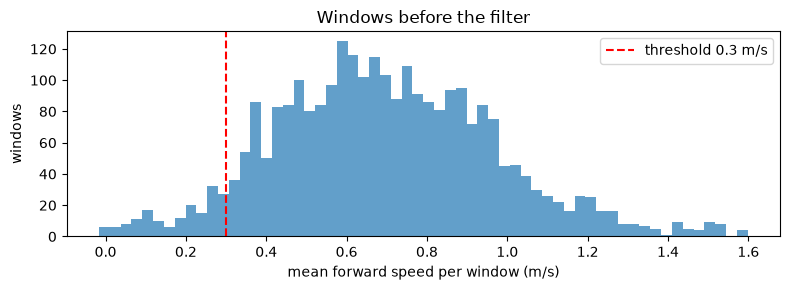


remaining: (2570, 60, 134) | slowest kept window: 0.3 m/s


In [7]:
is_walk = (meta.fwd_speed_mps >= MIN_WINDOW_FWD_SPEED).values
dropped = meta[~is_walk]
print(f"{(~is_walk).sum()} of {len(meta)} windows dropped (mean forward speed < {MIN_WINDOW_FWD_SPEED} m/s), "
      f"{is_walk.sum()} kept")
if len(dropped):
    dropped.to_csv(OUT_DIR / "dropped_windows.csv", index=False)
    print("\nDropped windows by clip type:")
    print(dropped.assign(kind=np.select([dropped.turning, dropped.stylized], ["turning", "stylized"], "plain"))
          .groupby(["text_category", "kind"]).size().to_string())
    print("\nMost common descriptions among the dropped windows:")
    print(dropped.description.str.lower().value_counts().head(10).to_string())

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(meta.fwd_speed_mps, bins=60, color="tab:blue", alpha=.7)
ax.axvline(MIN_WINDOW_FWD_SPEED, color="red", ls="--", label=f"threshold {MIN_WINDOW_FWD_SPEED} m/s")
ax.set(xlabel="mean forward speed per window (m/s)", ylabel="windows", title="Windows before the filter"); ax.legend()
plt.tight_layout(); plt.show()

# apply the filter to every array (safe to re-run: it only removes windows that are still too slow)
X_full, X_nr, JW = X_full[is_walk], X_nr[is_walk], JW[is_walk]
if SAVE_ROTATIONS:
    POSES, TRANS, BETAS, GENDER, CANON = POSES[is_walk], TRANS[is_walk], BETAS[is_walk], GENDER[is_walk], CANON[is_walk]
meta = meta[is_walk].reset_index(drop=True)
print("\nremaining:", X_full.shape, "| slowest kept window:", round(float(meta.fwd_speed_mps.min()), 2), "m/s")

In [ ]:
# 📊 For the slides — Step 7b: which windows were dropped as "not walking"
all_w = pd.concat([meta.assign(kept=True), dropped.assign(kept=False)], ignore_index=True)
all_w["kind"] = clip_kind(all_w)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw=dict(width_ratios=[1.3, 1, 1.2]))
bins = np.linspace(0, all_w.fwd_speed_mps.max() * 1.02, 50)
ax[0].hist([all_w.fwd_speed_mps[~all_w.kept], all_w.fwd_speed_mps[all_w.kept]], bins=bins, stacked=True,
           color=[STATUS_COLORS["dropped"], SERIES[0]], edgecolor="white", label=[f"dropped ({(~all_w.kept).sum()})", f"kept ({all_w.kept.sum()})"])
ax[0].axvline(MIN_WINDOW_FWD_SPEED, color=INK, ls="--", lw=1.3, label=f"threshold {MIN_WINDOW_FWD_SPEED} m/s")
ax[0].axvspan(1.2, 1.4, color=GRID, alpha=0.7, lw=0, zorder=0, label="typical adult walking speed")
ax[0].set(title="Forward speed of all windows", xlabel="mean forward speed (m/s)", ylabel="windows"); ax[0].legend(fontsize=9); grid(ax[0], "y")

rate = all_w.groupby("kind").kept.apply(lambda k: 100 * (~k).mean()).reindex([k for k in KIND_COLORS if k in set(all_w.kind)])
n_drop = all_w.groupby("kind").kept.apply(lambda k: (~k).sum()).reindex(rate.index)
y = np.arange(len(rate))[::-1]
ax[1].barh(y, rate.values, color=[KIND_COLORS[k] for k in rate.index], height=0.6, edgecolor="white", lw=2)
ax[1].set_yticks(y, rate.index); ax[1].tick_params(axis="y", length=0, labelcolor=INK)
for yi, r, n in zip(y, rate.values, n_drop.values):
    ax[1].text(r + 0.3, yi, f"{r:.1f}%  ({n})", va="center", fontsize=11, color=INK2)
ax[1].set_xlim(0, rate.max() * 1.4 + 1); ax[1].set(title="Share dropped per clip type", xlabel="% of windows dropped"); grid(ax[1], "x")

desc = dropped.description.str.lower().value_counts().head(8)
hbar(ax[2], [d[:32] for d in desc.index], desc.values, STATUS_COLORS["dropped"], total=len(dropped))
ax[2].set(title="Most common clips among dropped windows", xlabel="windows")
fig.tight_layout(); save_fig(fig, "11_non_walking_windows")

key_facts("Step 7b — non-walking windows",
    f"{len(dropped)} of {len(all_w)} windows dropped ({100 * len(dropped) / len(all_w):.1f}%), {len(meta)} kept",
    f"highest drop rate: {rate.idxmax()} clips ({rate.max():.1f}% of their windows)",
    f"kept windows: median forward speed {meta.fwd_speed_mps.median():.2f} m/s, slowest {meta.fwd_speed_mps.min():.2f} m/s",
    f"top dropped clip: '{desc.index[0]}' ({desc.iloc[0]} windows)" if len(desc) else "nothing dropped")

### 🎤 Talking points — Step 7b: dropping non-walking windows
**What the slide shows:** after cutting clips into 2-second windows, some windows don't show walking: the person stands, waits, or turns on the spot. Those windows are removed.

**Your numbers (last run):** **165 of 2,735 windows (6%)** dropped, **2,570 kept**. Most come from stylised walks (58) and turning clips (52 + 15 mixed); the most common source is "walk/wander" (39 windows).

**How to explain it:**
- A clip labelled "walk" can still contain standing or turning moments. Notebook 01 checked the **whole clip**; this step checks each **2-second piece**.
- The rule is simple: mean forward speed **below 0.3 m/s** → not walking. For comparison, very slow walking is ~0.5 m/s, a normal pace ~1.3 m/s.
- Stylised and turning clips lose the most windows. That makes sense: a "drunk walk" or "walk forward, turn around, walk back" contains slow or on-the-spot moments by design.
- Dropped windows are not lost: they are listed in `dropped_windows.csv` and can be inspected or reused.

## Step 8 — Split by person

In [8]:
person = {s: s for s in meta.subject.unique()}
for group in SAME_PERSON:
    for s in group:
        person[s] = min(group)
meta["person"] = meta.subject.map(person)

rng = np.random.default_rng(SEED)
persons = meta.person.unique()
rng.shuffle(persons)
counts = meta.person.value_counts()
total = counts.sum()
split_of, filled = {}, {"test": 0, "val": 0}
for p in persons:
    if len(persons) >= 3 and filled["test"] == 0:
        target = "test"
    elif len(persons) >= 3 and filled["val"] == 0:
        target = "val"
    elif filled["test"] < SPLIT_RATIOS[2] * total:
        target = "test"
    elif filled["val"] < SPLIT_RATIOS[1] * total:
        target = "val"
    else:
        target = "train"
    split_of[p] = target
    if target in filled:
        filled[target] += counts[p]
meta["split"] = meta.person.map(split_of)

summary = meta.groupby("split").agg(windows=("window_id", "size"), persons=("person", "nunique"),
                                    mean_speed=("fwd_speed_mps", "mean"), min_speed=("fwd_speed_mps", "min"),
                                    max_speed=("fwd_speed_mps", "max")).round(2)
print(summary)
for a in ["train", "val", "test"]:
    for b in ["train", "val", "test"]:
        if a < b:
            assert not set(meta.person[meta.split == a]) & set(meta.person[meta.split == b]), "person in two splits!"
print("\nNo person appears in two splits.")

       windows  persons  mean_speed  min_speed  max_speed
split                                                    
test       591       13        0.73       0.30       1.49
train     1513       23        0.72       0.30       1.59
val        466       14        0.76       0.32       1.60

No person appears in two splits.


In [ ]:
# 📊 For the slides — Step 8: split by person
splits = ["train", "val", "test"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw=dict(width_ratios=[1, 1.2, 1.2]))

# (a) windows per split vs. target
wc = meta.split.value_counts().reindex(splits)
pc = meta.groupby("split").person.nunique().reindex(splits)
target = np.array(SPLIT_RATIOS) * len(meta)
ax[0].bar(splits, wc.values, color=[SPLIT_COLORS[s] for s in splits], width=0.6)
ax[0].scatter(splits, target, marker="_", s=900, color=INK, lw=2, zorder=3, label="target")
for i, s in enumerate(splits):
    ax[0].text(i, max(wc[s], target[i]) + len(meta) * 0.03, f"{wc[s]} windows\n{pc[s]} persons\n({100 * wc[s] / len(meta):.0f}%)", ha="center", fontsize=10)
ax[0].set_ylim(0, max(wc.max(), target.max()) * 1.4); ax[0].set(title="Windows per split", ylabel="windows"); ax[0].legend(loc="upper right"); grid(ax[0], "y")

# (b) speed per split
bins = np.linspace(meta.fwd_speed_mps.min(), meta.fwd_speed_mps.max(), 35)
for s in splits:
    v = meta.fwd_speed_mps[meta.split == s]
    ax[1].hist(v, bins=bins, histtype="step", lw=2.2, density=True, color=SPLIT_COLORS[s], label=f"{s} (median {v.median():.2f} m/s)")
ax[1].set(title="Speed distribution per split", xlabel="forward speed (m/s)", ylabel="density"); ax[1].legend(fontsize=9); grid(ax[1], "y")

# (c) clip mix per split
mix = pd.crosstab(meta.split, clip_kind(meta), normalize="index").reindex(splits) * 100
mix = mix[[k for k in KIND_COLORS if k in mix]]
left = np.zeros(len(splits))
for k in mix.columns:
    ax[2].barh(range(len(splits))[::-1], mix[k].values, left=left, color=KIND_COLORS[k], height=0.6, edgecolor="white", lw=1.5, label=k)
    left += mix[k].values
ax[2].set_yticks(range(len(splits))[::-1], splits); ax[2].tick_params(axis="y", length=0, labelcolor=INK)
ax[2].set_xlim(0, 100); ax[2].set(xlabel="% of windows"); ax[2].set_title("Clip types per split", pad=30)
ax[2].legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
fig.tight_layout(); save_fig(fig, "12_split_by_person")

overlap = sum(len(set(meta.person[meta.split == a]) & set(meta.person[meta.split == b])) for a, b in [("train", "val"), ("train", "test"), ("val", "test")])
key_facts("Step 8 — split by person",
    *[f"{s}: {wc[s]} windows ({100 * wc[s] / len(meta):.0f}%, target {100 * r:.0f}%) from {pc[s]} persons" for s, r in zip(splits, SPLIT_RATIOS)],
    f"persons that appear in two splits: {overlap}",
    *[f"{s} median speed: {meta.fwd_speed_mps[meta.split == s].median():.2f} m/s" for s in splits])

### 🎤 Talking points — Step 8: split by person
**What the slide shows:** how the windows are divided into training, validation and test data, and that the three parts look alike (speed and clip types).

**Your numbers (last run):** train **1,513** windows / 23 persons, val **466** / 14, test **591** / 13. **No person is in two splits.**

**How to explain it:**
- The split is **by person, not by window**. Why? Every person has a recognisable way of walking. If the same person appeared in training *and* test, the model could score well just by recognising them, and the test result would be too optimistic (this is called **data leakage**).
- Overlapping windows make this even more important: two neighbouring windows share half their frames, so a random window split would put almost identical data in both sets.
- Because people contribute very different numbers of windows, the split can't hit 70/15/15 exactly. Whole persons are assigned until each split reaches its target.
- The speed and clip-type plots show the three splits are comparable, so the test set is a fair check.

**Interesting fact:** walking style is personal enough that **gait recognition** (identifying people from how they walk) is an active research field. That is exactly why a person-level split matters.

## Step 9 — Normalise (statistics from train only)
Foot-contact columns (0/1) are left as they are.

In [9]:
def norm_stats(X, contact_cols):
    flat = X.reshape(-1, X.shape[-1]).astype(np.float64)
    mean, std = flat.mean(0), flat.std(0)
    std[std < 1e-6] = 1.0
    mean[contact_cols], std[contact_cols] = 0.0, 1.0
    return mean.astype(np.float32), std.astype(np.float32)

train = (meta.split == "train").values
mean, std = norm_stats(X_full[train], CONTACT_COLS)
mean_nr, std_nr = norm_stats(X_nr[train], CONTACT_COLS_NR)

for split in ["train", "val", "test"]:
    m = (meta.split == split).values
    np.savez_compressed(OUT_DIR / f"{split}.npz",
                        X=(X_full[m] - mean) / std,          # normalised features (N, T, D)
                        X_noroot=(X_nr[m] - mean_nr) / std_nr,
                        joints=JW[m],                        # canonical joint positions (N, T, 22, 3), metres
                        window_id=meta.window_id[m].values,
                        **(dict(poses=POSES[m],              # (N, T, 156) SMPL+H axis-angle, canonical frame, 30 Hz
                                trans=TRANS[m],              # (N, T, 3)   SMPL+H translation, canonical frame
                                betas=BETAS[m],              # (N, 16)     body shape
                                gender=GENDER[m],            # (N,)        body model to use
                                canon=CANON[m])              # (N, 4)      [yaw, x, y, floor] used to canonicalise
                           if SAVE_ROTATIONS else {}))
    meta[m].to_csv(OUT_DIR / f"{split}_meta.csv", index=False)

np.savez(OUT_DIR / "normalization.npz", mean=mean, std=std, mean_noroot=mean_nr, std_noroot=std_nr)
config = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, tuple, list, dict, bool))}
config.update(FEATURES=FEATURES, FEATURES_NOROOT=FEATURES_NOROOT, JOINT_NAMES=JOINT_NAMES,
              BONES=[[int(a), int(b)] for a, b in BONES], coordinate_system="z-up, metres, window starts at origin facing +x")
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2, default=str))
print("saved to", OUT_DIR)
print(sorted(p.name for p in OUT_DIR.iterdir()))

saved to C:\Users\hasna\Documents\Good Practise\CMU\walking\preprocessed
['baseline_regression_results.csv', 'config.json', 'dropped_windows.csv', 'normalization.npz', 'quality_report.csv', 'test.npz', 'test_meta.csv', 'train.npz', 'train_meta.csv', 'val.npz', 'val_meta.csv']


In [ ]:
# 📊 For the slides — Step 9: normalisation
raw_std = X_full[train].reshape(-1, X_full.shape[-1]).std(0)
grp_color = np.array([SERIES[1]] * 4 + [SERIES[0]] * 63 + [SERIES[2]] * 63 + [SERIES[3]] * 4)

fig = plt.figure(figsize=(17, 8))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1])
ax = fig.add_subplot(gs[0, :])
ax.bar(np.arange(len(raw_std)), raw_std, color=grp_color, width=1.0)
ax.set_yscale("log"); ax.set_xlim(-1, len(raw_std))
ax.set(title="Before: spread (std) of every feature in the training data — the scales differ a lot", xlabel="feature index", ylabel="std (log scale)")
leg = [("root", SERIES[1]), ("positions (m)", SERIES[0]), ("velocities (m/s)", SERIES[2]), ("contacts (not normalised)", SERIES[3])]
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for _, c in leg], [l for l, _ in leg], ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title(ax.get_title(), pad=30); grid(ax, "y")

examples = ["root_height", "root_vel_forward", "vel_L_wrist_x" if "vel_L_wrist_x" in FEATURES else FEATURES[70]]
for k, f in enumerate(examples):
    ax = fig.add_subplot(gs[1, k]); fi = FEATURES.index(f)
    for s in ["train", "val", "test"]:
        m = (meta.split == s).values
        v = ((X_full[m][..., fi] - mean[fi]) / std[fi]).ravel()
        ax.hist(v, bins=60, range=(-4, 4), histtype="step", lw=2, density=True, color=SPLIT_COLORS[s],
                label=f"{s}: mean {v.mean():+.2f}, std {v.std():.2f}")
    ax.set(title=f"After: {f}", xlabel=f"normalised value (raw: {mean[fi]:.2f} ± {std[fi]:.2f})", ylabel="density")
    ax.legend(fontsize=8, loc="upper left"); grid(ax, "y")
fig.tight_layout(); save_fig(fig, "13_normalisation")

nz = raw_std[raw_std > 1e-6]
key_facts("Step 9 — normalisation",
    f"feature spreads range from {nz.min():.3f} to {nz.max():.2f} → a factor of {nz.max() / nz.min():.0f}× before normalising",
    "mean and std come from the TRAINING windows only, then the same numbers are applied to val and test",
    f"after normalising: train mean {((X_full[train] - mean) / std)[..., 4:-4].mean():+.3f}, std {((X_full[train] - mean) / std)[..., 4:-4].std():.3f}",
    "foot-contact columns (0/1) are left as they are")

### 🎤 Talking points — Step 9: normalisation
**What the slide shows:** before normalising, features live on very different scales (a joint position spreads by centimetres, a hand velocity by metres per second). Afterwards, every feature is centred at 0 with spread 1.

**How to explain it:**
- Neural networks train faster and more stably when all inputs have a similar size. Otherwise the largest features dominate the loss.
- **Statistics from train only:** the mean and std are computed on the training windows and then applied unchanged to validation and test. Computing them on all data would leak information about the test set into training.
- The val/test curves on the slide are close to mean 0 / std 1 but not exactly, and that is expected and correct. It also shows the splits are similar.
- **Foot contacts stay 0/1** so they remain easy to read and can be used directly with a binary loss.
- The stored `mean` and `std` (`normalization.npz`) are needed later to turn the model's output back into metres: `x * std + mean`.

## Step 10 — Checks
**Round trip:** rebuild joint positions from the features and compare with the originals. The error should be close to zero. This also tests `recover_joints`, which you will reuse on decoded motion.

**Rotation round trip:** run the saved SMPL+H rotations (`poses`, `trans`, `betas`) through the body model and compare with the saved joints. If this is ~0, the rotations describe exactly the same motion as the features.

In [10]:
err = np.array([np.abs(recover_joints(X_full[i]) - JW[i]).max() for i in range(len(JW))])
print(f"max joint error after feature -> joints round trip: {err.max()*1000:.4f} mm")
assert err.max() < 1e-3, "round trip failed"

chk = np.load(OUT_DIR / "train.npz")
nrm = np.load(OUT_DIR / "normalization.npz")
x0 = chk["X"][0] * nrm["std"] + nrm["mean"]
print("de-normalised train window matches:", np.allclose(recover_joints(x0), chk["joints"][0], atol=1e-3))
if SAVE_ROTATIONS:
    err_rot = np.array([np.abs(body_joints(load_body_model(GENDER[i]), BETAS[i], POSES[i].astype(np.float64),
                                           TRANS[i].astype(np.float64)) - JW[i]).max() for i in range(len(JW))])
    print(f"max joint error, saved rotations -> body model -> joints: {err_rot.max()*1000:.4f} mm")
    assert err_rot.max() < 2e-3, "rotation round trip failed"
    print("saved rotation keys in train.npz:", [k for k in chk.files if k in ("poses", "trans", "betas", "gender", "canon")])
print("train feature mean/std after normalising (should be ~0 / ~1):",
      round(float(chk["X"][..., 4:-4].mean()), 3), round(float(chk["X"][..., 4:-4].std()), 3))

max joint error after feature -> joints round trip: 0.0008 mm
de-normalised train window matches: True
max joint error, saved rotations -> body model -> joints: 0.0003 mm
saved rotation keys in train.npz: ['poses', 'trans', 'betas', 'gender', 'canon']
train feature mean/std after normalising (should be ~0 / ~1): -0.0 1.0


In [ ]:
# 📊 For the slides — Step 10: round-trip checks
fig, ax = plt.subplots(1, 2 if SAVE_ROTATIONS else 1, figsize=(15 if SAVE_ROTATIONS else 8, 3.8), squeeze=False)
checks = [("features → joints", err, SERIES[0])] + ([("SMPL+H rotations → body model → joints", err_rot, SERIES[2])] if SAVE_ROTATIONS else [])
for a, (lab, e, c) in zip(ax[0], checks):
    e_mm = np.maximum(e * 1000, 1e-9)
    a.hist(np.log10(e_mm), bins=40, color=c, edgecolor="white")
    a.set_xticks(a.get_xticks(), [f"$10^{{{int(t)}}}$" for t in a.get_xticks()])
    a.set(title=f"{lab}\nmax error {e_mm.max():.4f} mm", xlabel="max joint error per window (mm, log scale)", ylabel="windows"); grid(a, "y")
fig.tight_layout(); save_fig(fig, "14_round_trip")
key_facts("Step 10 — checks",
    f"features → joints: max error {err.max() * 1000:.4f} mm over {len(err):,} windows",
    *([f"rotations → body model → joints: max error {err_rot.max() * 1000:.4f} mm"] if SAVE_ROTATIONS else []),
    f"for scale: a human hair is ~0.07 mm thick, ~{0.07 / max(err.max() * 1000, 1e-9):.0f}× more than the largest error")

### 🎤 Talking points — Step 10: checks
**What the slide shows:** two "round trips". We rebuild the 3D skeleton from the saved data and compare it with the original.

**Your numbers (last run):** features → joints: **max 0.0008 mm**. Rotations → body model → joints: **max 0.0003 mm**.

**How to explain it:**
- **Round trip 1:** the features store speeds, not positions. To get positions back, `recover_joints` adds up the speeds over time. If any sign, angle or axis were wrong, the error would grow along the window. It doesn't.
- **Round trip 2:** the SMPL+H rotations were moved and turned separately from the joints. Running them through the body model gives the same skeleton, so both representations describe exactly the same motion.
- Errors of a few ten-thousandths of a millimetre are just **rounding** (data is saved as 32-bit floats). For scale, a human hair is about 0.07 mm thick.
- Why it matters: `recover_joints` is the function that will turn **model output** back into a skeleton, so it has to be exact.

**Stick figures:** a few frames from random windows (side view), plus the root path from above. Each should look like a person walking towards +x with feet on the floor (z = 0).

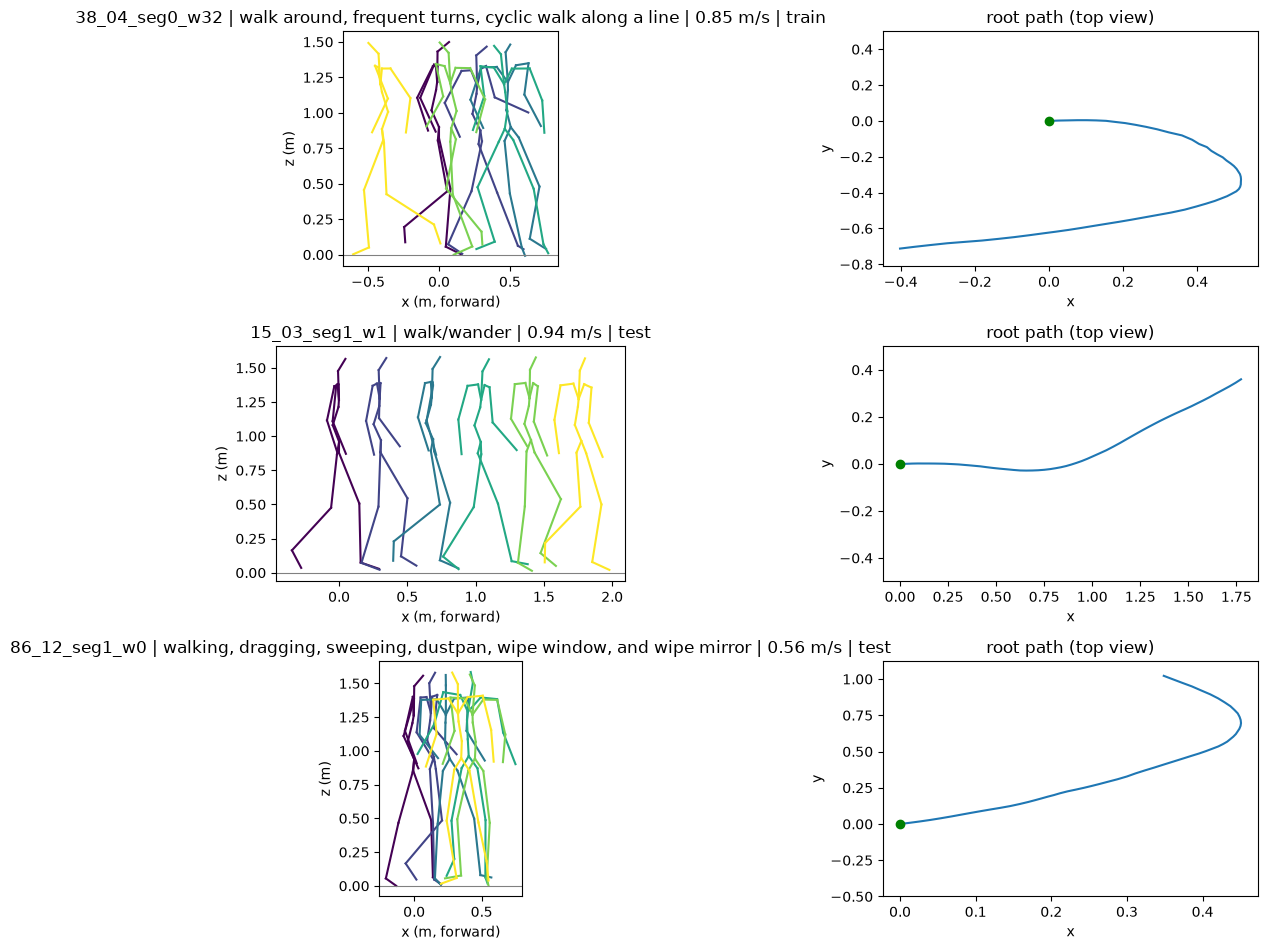

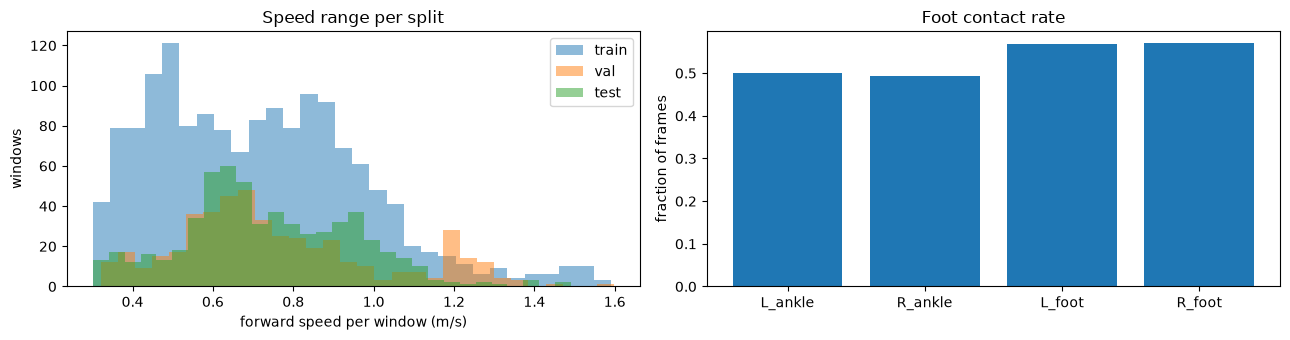

In [11]:
def draw(ax, P, color, alpha=1.0):
    for j, p in BONES:
        ax.plot([P[j, 0], P[p, 0]], [P[j, 2], P[p, 2]], color=color, alpha=alpha, lw=1.5)

rng_plot = np.random.default_rng(0)
picks = rng_plot.choice(len(JW), size=min(3, len(JW)), replace=False)
fig, axes = plt.subplots(len(picks), 2, figsize=(14, 3.2 * len(picks)), gridspec_kw={"width_ratios": [3, 1]}, squeeze=False)
for row, i in zip(axes, picks):
    W = JW[i]
    for k, t in enumerate(np.linspace(0, len(W) - 1, 6).astype(int)):
        draw(row[0], W[t], plt.cm.viridis(k / 5))
    row[0].axhline(0, color="grey", lw=.8); row[0].set_aspect("equal")
    m = meta.iloc[i]
    row[0].set_title(f"{m.window_id} | {m.description} | {m.fwd_speed_mps:.2f} m/s | {m.split}")
    row[0].set(xlabel="x (m, forward)", ylabel="z (m)")
    row[1].plot(W[:, 0, 0], W[:, 0, 1]); row[1].plot(0, 0, "go")
    row[1].set_ylim(min(-0.5, W[:, 0, 1].min() - .1), max(0.5, W[:, 0, 1].max() + .1))
    row[1].set(title="root path (top view)", xlabel="x", ylabel="y")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for split in ["train", "val", "test"]:
    ax[0].hist(meta.fwd_speed_mps[meta.split == split], bins=30, alpha=.5, label=split)
ax[0].set(xlabel="forward speed per window (m/s)", ylabel="windows", title="Speed range per split"); ax[0].legend()
c = X_full[..., CONTACT_COLS].mean((0, 1))
ax[1].bar(FOOT_NAMES, c); ax[1].set(ylabel="fraction of frames", title="Foot contact rate")
plt.tight_layout(); plt.show()

**What to expect on real data:** each foot should be in contact for roughly 55–65 % of frames when walking. Much lower means the contact thresholds (`CONTACT_VEL`, `CONTACT_HEIGHT`) are too strict; much higher means they are too loose.

## Step 10b — Compare with the official SMPL+H code
This notebook computes the joints with its own short forward kinematics (Step 1). Here the same frames go through the official implementation (`smplx`, or `human_body_prior` as used in AMASS) and the 22 body joints are compared. The error should be well below 1 mm.

Needs `pip install smplx torch` (or `human_body_prior`). If neither is installed the cell just says so; nothing else depends on it.

*Note:* `smplx` uses only the first 10 shape values (`betas`) of the AMASS model files, so both sides use the same number of betas in this comparison.

In [12]:
def official_body_joints(gender, betas, poses, trans):
    # 22 body joints from the official SMPL+H code -> (joints (T, 22, 3), number of betas used, library name)
    import torch
    path = BODY_MODEL_DIR / gender / "model.npz"
    T = len(poses)
    f = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
    try:
        import smplx
        from smplx.utils import Struct
        md = dict(np.load(path, allow_pickle=True))
        for side in "lr":       # AMASS model files have no hand PCA; we pass full hand rotations instead
            md.setdefault(f"hands_components{side}", np.eye(45))
            md.setdefault(f"hands_mean{side}", np.zeros(45))
        bm = smplx.SMPLH(model_path=str(path), data_struct=Struct(**md), gender=gender, num_betas=16,
                         use_pca=False, flat_hand_mean=True, batch_size=T)
        K = bm.shapedirs.shape[-1]
        b = np.zeros((T, K)); n = min(K, len(betas)); b[:, :n] = betas[:n]
        with torch.no_grad():
            out = bm(global_orient=f(poses[:, :3]), body_pose=f(poses[:, 3:66]),
                     left_hand_pose=f(poses[:, 66:111]), right_hand_pose=f(poses[:, 111:156]),
                     betas=f(b), transl=f(trans))
        return out.joints[:, :N_BODY].numpy().astype(np.float64), K, "smplx"
    except ImportError:
        pass
    from human_body_prior.body_model.body_model import BodyModel
    try:
        bm = BodyModel(bm_fname=str(path), num_betas=16)
    except TypeError:                                   # older human_body_prior versions
        bm = BodyModel(bm_path=str(path), model_type="smplh", num_betas=16)
    b = np.zeros((T, 16)); n = min(16, len(betas)); b[:, :n] = betas[:n]
    with torch.no_grad():
        out = bm(root_orient=f(poses[:, :3]), pose_body=f(poses[:, 3:66]), pose_hand=f(poses[:, 66:156]),
                 betas=f(b), trans=f(trans))
    return out.Jtr[:, :N_BODY].cpu().numpy().astype(np.float64), 16, "human_body_prior"

# pick segments of different genders if possible
ids = list(joints_hr)
by_g = {}
for sid in ids:
    by_g.setdefault(load_body_model(clean[sid]["gender"])["gender"], []).append(sid)
rng_fk = np.random.default_rng(SEED)
picks = []
while len(picks) < min(FK_CHECK_SEGMENTS, len(ids)):
    for g in sorted(by_g):
        rest = [s for s in by_g[g] if s not in picks]
        if rest and len(picks) < FK_CHECK_SEGMENTS:
            picks.append(rest[rng_fk.integers(len(rest))])

fk_rows, fk_example = [], None
try:
    for sid in picks:
        d = clean[sid]
        model = load_body_model(d["gender"])
        sl = slice(0, min(len(d["poses"]), 600))                       # at most 5 s at 120 Hz is enough
        J_off, K, lib = official_body_joints(model["gender"], d["betas"], d["poses"][sl], d["trans"][sl])
        J_own = body_joints(model, d["betas"][:K], d["poses"][sl], d["trans"][sl])
        e = np.linalg.norm(J_own - J_off, axis=-1) * 1000
        fk_rows.append(dict(segment_id=sid, gender=model["gender"], library=lib, n_betas=K, frames=len(J_own),
                            mean_error_mm=e.mean(), max_error_mm=e.max()))
        if fk_example is None:
            fk_example = (sid, J_own, J_off)
except ImportError as ex:
    print("Official SMPL+H code not installed, check skipped:", ex)
    print("Install with:  pip install smplx torch   (or human_body_prior)")

if fk_rows:
    fk = pd.DataFrame(fk_rows)
    print(fk.round(4).to_string(index=False))
    ok = fk.max_error_mm.max() < 1.0
    print("\nOwn forward kinematics matches the official SMPL+H code:", ok)
    fk.to_csv(OUT_DIR / "fk_check.csv", index=False)

    sid, J_own, J_off = fk_example
    t = 0
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    for a, (u, name) in zip(ax, [(0, "front (x-z)"), (1, "side (y-z)")]):
        for j, p in BONES:
            a.plot([J_off[t, j, u], J_off[t, p, u]], [J_off[t, j, 2], J_off[t, p, 2]], color="tab:blue", lw=4, alpha=.35)
            a.plot([J_own[t, j, u], J_own[t, p, u]], [J_own[t, j, 2], J_own[t, p, 2]], color="tab:red", lw=1.2)
        a.plot([], [], color="tab:blue", lw=4, alpha=.35, label="official"); a.plot([], [], color="tab:red", label="this notebook")
        a.set_aspect("equal"); a.set(title=f"{sid}, frame {t}: {name}", xlabel="m", ylabel="z (m)"); a.legend()
    plt.tight_layout(); plt.show()

Official SMPL+H code not installed, check skipped: No module named 'human_body_prior'
Install with:  pip install smplx torch   (or human_body_prior)


## Step 11 — Visual exploration
Plots for one segment (set `VIS_SEGMENT` in the settings, e.g. `"07_04_seg0"`), then an overview of the whole dataset.

- **11a** root position over time, 3D trajectory, top view with facing direction
- **11b** all pose values and the rotation size of every joint over time
- **11c** body shape (`betas`) and soft-tissue values (`dmpls`, if the file has them)
- **11d** speed over time (raw, smoothed, forward) and hip/knee angles
- **11e** 3D skeleton of one frame and an animation of the segment
- **11f** dataset overview: speed per person, per window, per clip type, and all canonical root paths

Segment: 05_01_seg0 | walk
Source file: 05\05_01_poses.npz frames 0-540
Gender: female | 120 fps | 540 frames | 4.50 s | 52 joints | arrays in file: ['trans', 'gender', 'mocap_framerate', 'betas', 'dmpls', 'poses', 'source_file', 'source_start', 'source_end', 'description']
Path length 4.12 m | net displacement 4.09 m | mean path speed 0.92 m/s | turned -8 deg


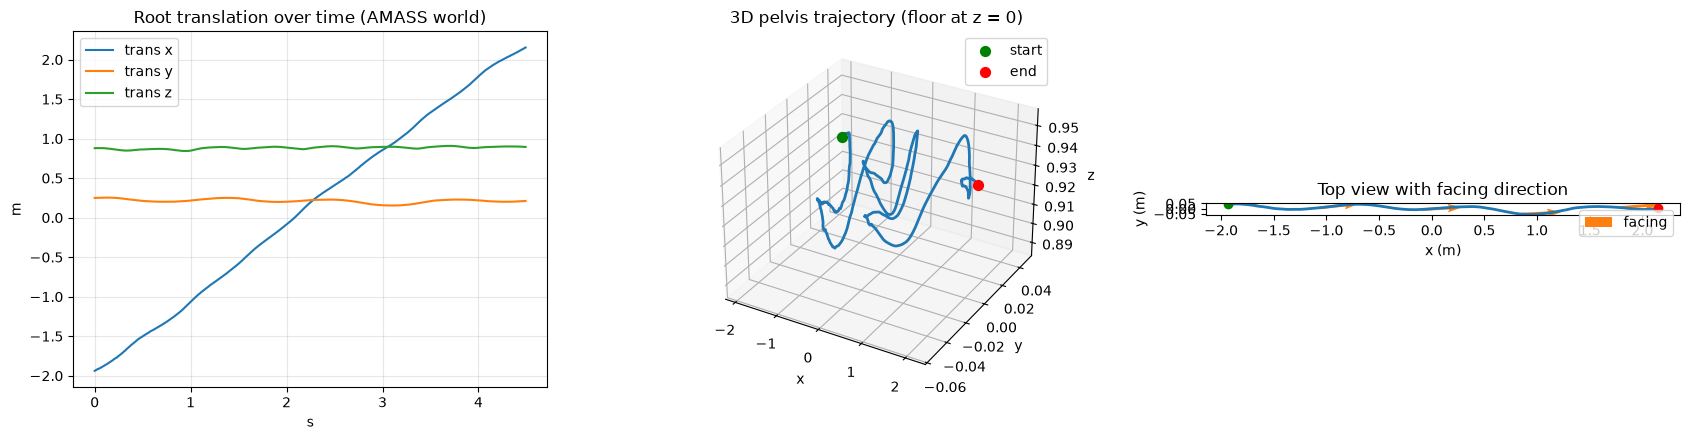

In [13]:
vis_sid = VIS_SEGMENT if VIS_SEGMENT in joints_hr else next(iter(joints_hr))
d_v, X_v = clean[vis_sid], joints_hr[vis_sid]             # rotations/translation and floor-aligned joints, original fps
fps_v = d_v["fps"]; T_v = len(X_v); t_v = np.arange(T_v) / fps_v
info_v = seg_info.loc[vis_sid]
raw_v = np.load(SEG_DIR / f"{vis_sid}.npz", allow_pickle=True)

pelvis = X_v[:, 0]
step = np.linalg.norm(np.diff(pelvis[:, :2], axis=0), axis=1)
th_v = heading(X_v)
print("=" * 60)
print("Segment:", vis_sid, "|", info_v.description)
print("Source file:", info_v.rel_path, f"frames {info_v.start_frame}-{info_v.end_frame}")
print(f"Gender: {d_v['gender']} | {fps_v:g} fps | {T_v} frames | {T_v / fps_v:.2f} s | "
      f"{d_v['poses'].shape[1] // 3} joints | arrays in file: {raw_v.files}")
print(f"Path length {step.sum():.2f} m | net displacement {np.linalg.norm(pelvis[-1, :2] - pelvis[0, :2]):.2f} m | "
      f"mean path speed {step.sum() / ((T_v - 1) / fps_v):.2f} m/s | turned {np.degrees(th_v[-1] - th_v[0]):+.0f} deg")
print("=" * 60)

# 11a — root trajectory
fig = plt.figure(figsize=(17, 4.5))
ax = fig.add_subplot(1, 3, 1)
for i, n in enumerate("xyz"):
    ax.plot(t_v, d_v["trans"][:, i], label=f"trans {n}")
ax.set(title="Root translation over time (AMASS world)", xlabel="s", ylabel="m"); ax.legend(); ax.grid(alpha=.3)

ax = fig.add_subplot(1, 3, 2, projection="3d")
ax.plot(*pelvis.T, lw=2)
ax.scatter(*pelvis[0], color="green", s=50, label="start"); ax.scatter(*pelvis[-1], color="red", s=50, label="end")
ax.set(title="3D pelvis trajectory (floor at z = 0)", xlabel="x", ylabel="y", zlabel="z"); ax.legend()

ax = fig.add_subplot(1, 3, 3)
ax.plot(pelvis[:, 0], pelvis[:, 1], lw=2)
ax.plot(*pelvis[0, :2], "go"); ax.plot(*pelvis[-1, :2], "ro")
every = max(1, int(fps_v))                                 # one facing arrow per second
ax.quiver(pelvis[::every, 0], pelvis[::every, 1], np.cos(th_v[::every]), np.sin(th_v[::every]),
          color="tab:orange", scale=12, width=.006, label="facing")
ax.set_aspect("equal"); ax.set(title="Top view with facing direction", xlabel="x (m)", ylabel="y (m)"); ax.legend()
plt.tight_layout(); plt.show()

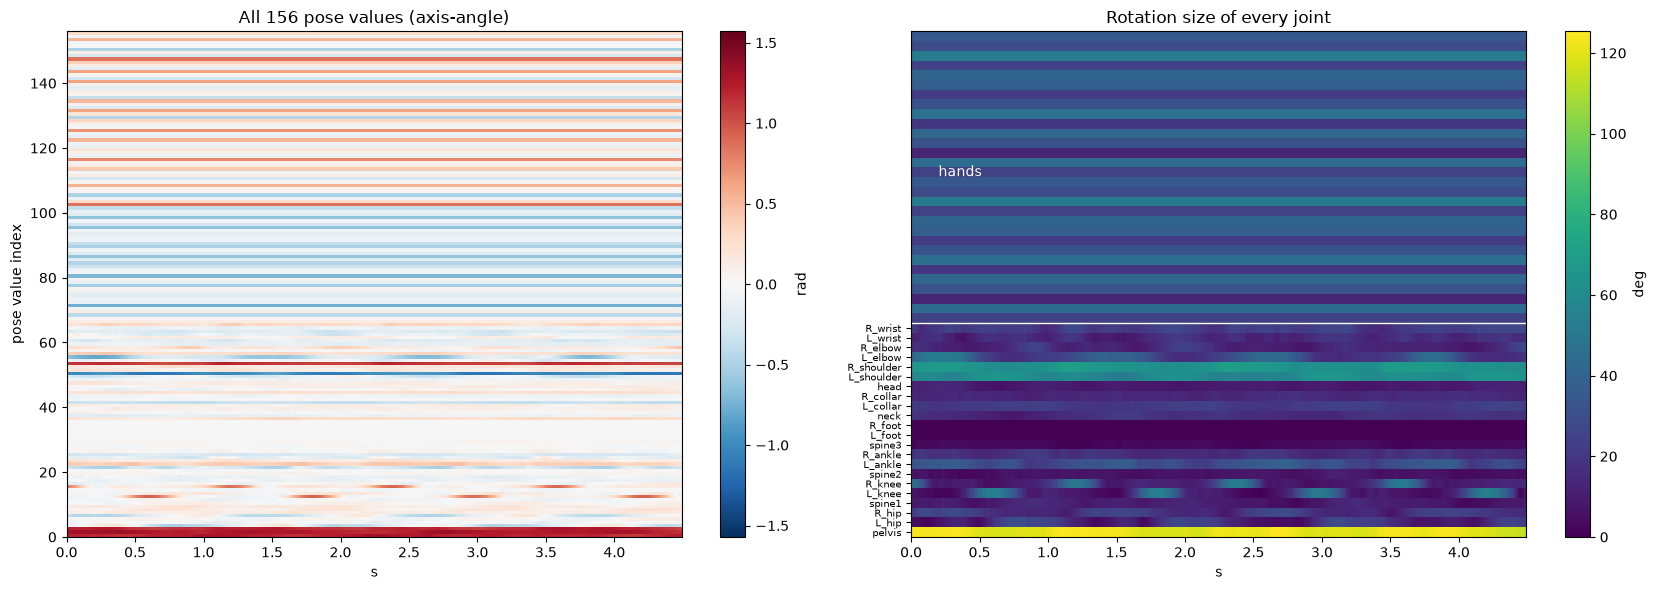

In [14]:
# 11b — pose values and joint rotation size
poses_v = d_v["poses"]
n_j = poses_v.shape[1] // 3
rot_deg = np.degrees(np.linalg.norm(poses_v.reshape(T_v, n_j, 3), axis=2))
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
im = ax[0].imshow(poses_v.T, aspect="auto", origin="lower", extent=[0, t_v[-1], 0, poses_v.shape[1]],
                  cmap="RdBu_r", vmin=-np.pi / 2, vmax=np.pi / 2, interpolation="nearest")
ax[0].set(title=f"All {poses_v.shape[1]} pose values (axis-angle)", xlabel="s", ylabel="pose value index")
fig.colorbar(im, ax=ax[0], label="rad")
im = ax[1].imshow(rot_deg.T, aspect="auto", origin="lower", extent=[0, t_v[-1], -0.5, n_j - 0.5],
                  cmap="viridis", interpolation="nearest")
ax[1].set_yticks(range(N_BODY), JOINT_NAMES, fontsize=7)
ax[1].axhline(N_BODY - 0.5, color="w", lw=1); ax[1].text(0.2, (N_BODY + n_j) / 2, "hands", color="w", va="center")
ax[1].set(title="Rotation size of every joint", xlabel="s")
fig.colorbar(im, ax=ax[1], label="deg")
plt.tight_layout(); plt.show()

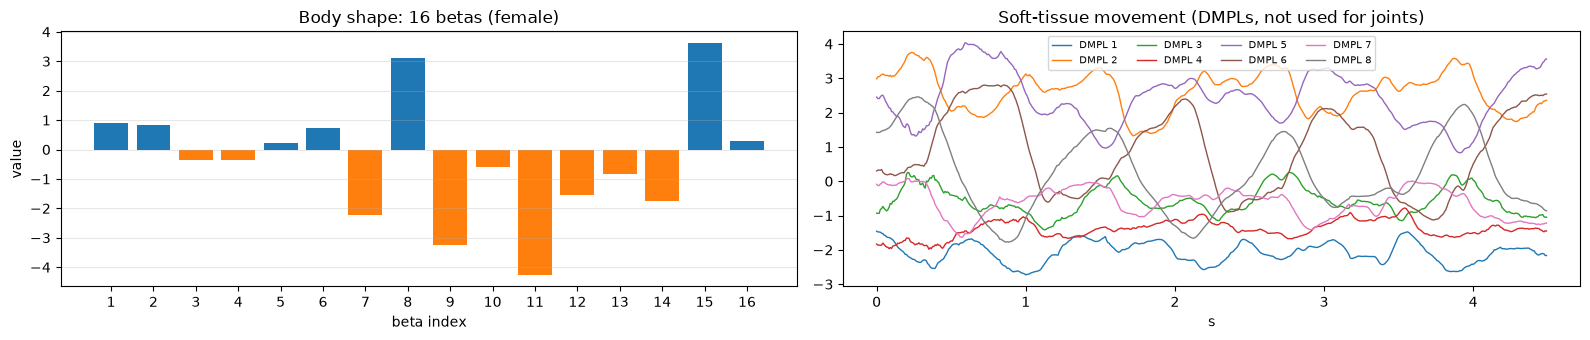

In [15]:
# 11c — body shape and soft tissue
has_dmpl = "dmpls" in raw_v.files
fig, ax = plt.subplots(1, 2 if has_dmpl else 1, figsize=(16 if has_dmpl else 8, 3.5), squeeze=False)
b_v = np.asarray(d_v["betas"]).ravel()
ax[0, 0].bar(np.arange(1, len(b_v) + 1), b_v, color=np.where(b_v >= 0, "tab:blue", "tab:orange"))
ax[0, 0].set(title=f"Body shape: {len(b_v)} betas ({d_v['gender']})", xlabel="beta index", ylabel="value")
ax[0, 0].set_xticks(np.arange(1, len(b_v) + 1)); ax[0, 0].grid(axis="y", alpha=.3)
if has_dmpl:
    dm = raw_v["dmpls"]
    for i in range(dm.shape[1]):
        ax[0, 1].plot(np.arange(len(dm)) / fps_v, dm[:, i], lw=1, label=f"DMPL {i + 1}")
    ax[0, 1].set(title="Soft-tissue movement (DMPLs, not used for joints)", xlabel="s"); ax[0, 1].legend(ncol=4, fontsize=7)
plt.tight_layout(); plt.show()

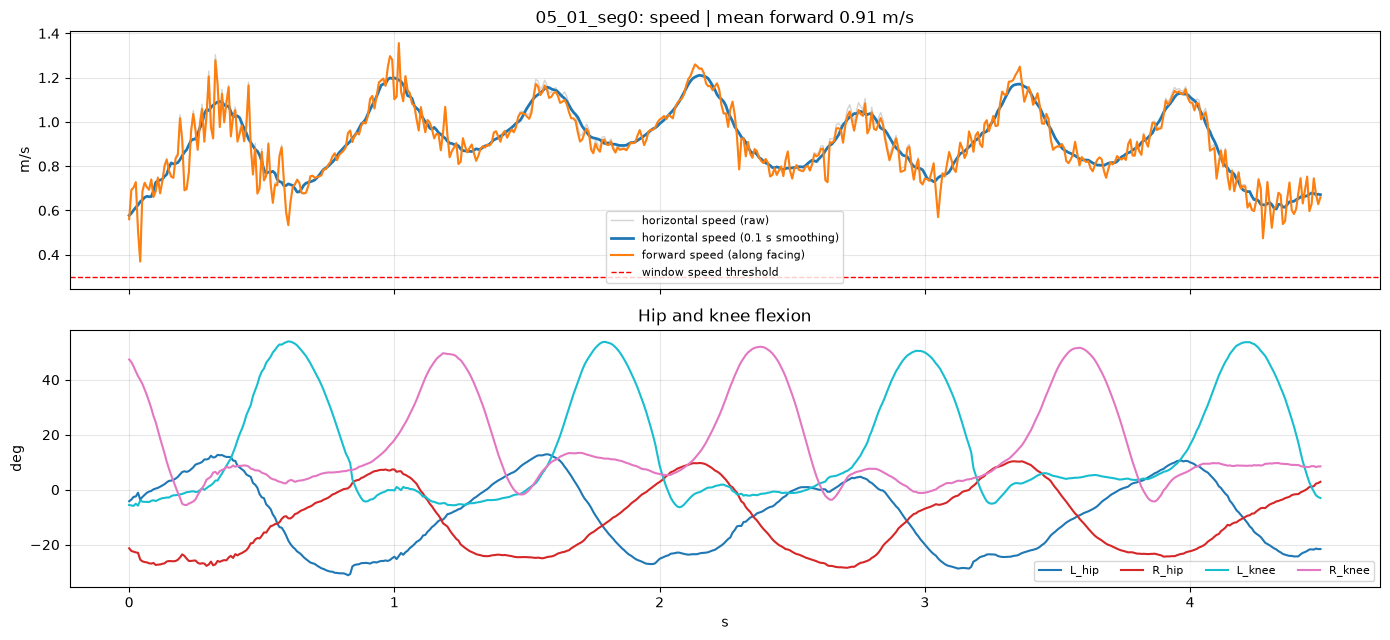

In [16]:
# 11d — speed and joint angles over time
from scipy.ndimage import uniform_filter1d
v_xy = np.gradient(pelvis[:, :2], axis=0) * fps_v
speed_raw = np.linalg.norm(v_xy, axis=1)
k = max(1, int(round(0.1 * fps_v)))
speed_smooth = uniform_filter1d(speed_raw, k, mode="nearest")
fwd = (v_xy * np.c_[np.cos(th_v), np.sin(th_v)]).sum(1)
flex = lambda j: np.degrees(Rotation.from_rotvec(poses_v[:, 3 * j:3 * j + 3]).as_euler("XYZ")[:, 0])

fig, ax = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
ax[0].plot(t_v, speed_raw, color="lightgray", lw=1, label="horizontal speed (raw)")
ax[0].plot(t_v, speed_smooth, lw=2, label="horizontal speed (0.1 s smoothing)")
ax[0].plot(t_v, fwd, lw=1.5, label="forward speed (along facing)")
ax[0].axhline(MIN_WINDOW_FWD_SPEED, color="red", ls="--", lw=1, label="window speed threshold")
ax[0].set(ylabel="m/s", title=f"{vis_sid}: speed | mean forward {fwd.mean():.2f} m/s"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
for j, c in [(J["L_hip"], "tab:blue"), (J["R_hip"], "tab:red"), (J["L_knee"], "tab:cyan"), (J["R_knee"], "tab:pink")]:
    ax[1].plot(t_v, flex(j), color=c, label=JOINT_NAMES[j])
ax[1].set(xlabel="s", ylabel="deg", title="Hip and knee flexion"); ax[1].legend(ncol=4, fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

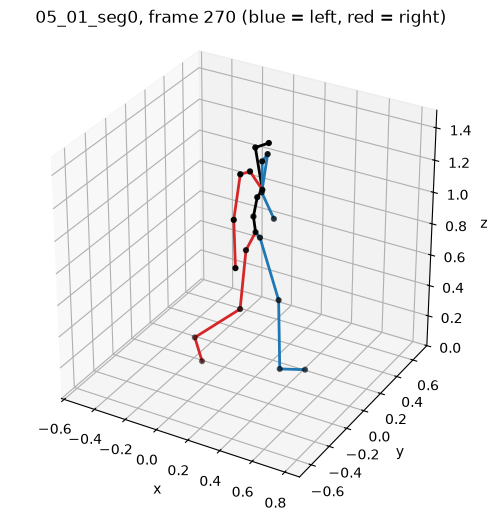

In [17]:
# 11e — 3D skeleton (one frame) and animation
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
plt.rcParams["animation.embed_limit"] = 50

side_color = lambda j: "tab:blue" if JOINT_NAMES[j].startswith("L_") else "tab:red" if JOINT_NAMES[j].startswith("R_") else "k"

def setup_3d(ax, P):
    lo, hi = P.reshape(-1, 3).min(0), P.reshape(-1, 3).max(0)
    c, r = (lo + hi) / 2, (hi - lo).max() / 2 * 1.05
    ax.set(xlim=(c[0] - r, c[0] + r), ylim=(c[1] - r, c[1] + r), zlim=(0, 2 * r), xlabel="x", ylabel="y", zlabel="z")
    ax.set_box_aspect((1, 1, 1))

t0 = T_v // 2
fig = plt.figure(figsize=(6, 6)); ax = fig.add_subplot(projection="3d")
setup_3d(ax, X_v[t0][None])
for j, p in BONES:
    ax.plot(*X_v[t0, [j, p]].T, color=side_color(j), lw=2)
ax.scatter(*X_v[t0].T, s=12, color="k")
ax.set_title(f"{vis_sid}, frame {t0} (blue = left, red = right)"); plt.show()

# animation: at most 6 s, shown at 12 fps (small figure keeps the notebook light)
ANIM_FPS = 12
frames = np.arange(0, min(T_v, int(6 * fps_v)), max(1, int(round(fps_v / ANIM_FPS))))
fig = plt.figure(figsize=(5, 5), dpi=60); ax = fig.add_subplot(projection="3d")
setup_3d(ax, X_v[frames])
ax.plot(pelvis[frames, 0], pelvis[frames, 1], 0 * frames, color="gray", lw=1)
lines = [ax.plot(*X_v[frames[0], [j, p]].T, color=side_color(j), lw=2)[0] for j, p in BONES]
title = ax.set_title("")
def update(i):
    P = X_v[frames[i]]
    for ln, (j, p) in zip(lines, BONES):
        ln.set_data(P[[j, p], 0], P[[j, p], 1]); ln.set_3d_properties(P[[j, p], 2])
    title.set_text(f"{vis_sid}  t = {frames[i] / fps_v:.2f} s")
    return lines
anim = FuncAnimation(fig, update, frames=len(frames), interval=1000 / ANIM_FPS)
plt.close(fig)
display(HTML(anim.to_jshtml()))

In [ ]:
# 11f — dataset overview (windows after the speed filter)
fig, ax = plt.subplots(2, 2, figsize=(17, 9))

# speed per person, coloured by split
order = meta.groupby("person").fwd_speed_mps.median().sort_values().index
colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}
bp = ax[0, 0].boxplot([meta.fwd_speed_mps[meta.person == p] for p in order], patch_artist=True, showfliers=False)
for patch, p in zip(bp["boxes"], order):
    patch.set_facecolor(colors[split_of[p]]); patch.set_alpha(.6)
ax[0, 0].set_xticks(range(1, len(order) + 1), order, fontsize=7, rotation=90)
for s, c in colors.items():
    ax[0, 0].plot([], [], color=c, lw=6, alpha=.6, label=s)
ax[0, 0].set(xlabel="person (subject)", ylabel="forward speed (m/s)", title="Speed per person"); ax[0, 0].legend()

# speed window by window inside a few segments
for sid in meta.segment_id.value_counts().index[:6]:
    w = meta[meta.segment_id == sid]
    ax[0, 1].plot(np.arange(len(w)), w.fwd_speed_mps, "o-", ms=3, label=f"{sid}: {str(w.description.iloc[0])[:25]}")
ax[0, 1].set(xlabel="window number in segment", ylabel="forward speed (m/s)", title="Speed from window to window (longest segments)")
ax[0, 1].legend(fontsize=7)

# speed by clip type
groups = {"plain walk": meta[(meta.text_category == "walk") & ~meta.stylized & ~meta.turning],
          "turning": meta[meta.turning], "stylised": meta[meta.stylized], "mixed": meta[meta.text_category == "mixed"]}
groups = {k: v for k, v in groups.items() if len(v)}
ax[1, 0].boxplot([g.fwd_speed_mps for g in groups.values()], showfliers=False)
ax[1, 0].set_xticks(range(1, len(groups) + 1), [f"{k}\n({len(v)} windows)" for k, v in groups.items()])
ax[1, 0].set(ylabel="forward speed (m/s)", title="Speed by clip type")

# all canonical root paths: every window starts at the origin facing +x
idx = np.random.default_rng(0).choice(len(JW), size=min(300, len(JW)), replace=False)
for i in idx:
    ax[1, 1].plot(JW[i, :, 0, 0], JW[i, :, 0, 1], lw=.6, alpha=.4, color=colors[meta.split.iloc[i]])
ax[1, 1].plot(0, 0, "ko")
ax[1, 1].set_aspect("equal"); ax[1, 1].set(xlabel="x (m, forward)", ylabel="y (m)", title=f"Root paths of {len(idx)} random windows (top view)")
plt.tight_layout(); plt.show()

### 🎤 Talking points — Step 11: visual exploration
- **Root trajectory and facing:** shows a single clip as recorded: where the person walked in the lab and which way they looked.
- **Pose heatmap:** every row is one rotation value over time. The repeating stripes are the **gait cycle**; the hand rows (top) are mostly flat because CMU did not capture fingers in detail.
- **Body shape:** 16 `betas` describe the person's body (height, weight, proportions). The first values matter most.
- **Hip and knee angles:** the knee bends twice per step: a small bend while the foot is on the ground (shock absorption) and a big bend (~60°) to lift the foot during the swing.
- **Dataset overview:** speed differs a lot between people. This is another reason why the split is done by person.

In [ ]:
# 📊 For the slides — summary: from raw clips to training data
seg_stages = [("selected segments", len(segs)),
              ("passed quality check (Step 0)", len(clean)),
              ("passed skeleton check (Step 1)", len(joints_hr))]
win_stages = [("windows cut (Step 4)", len(meta) + len(dropped)),
              ("walking windows (Step 7b)", len(meta)),
              *[(f"{s}", int((meta.split == s).sum())) for s in ["train", "val", "test"]]]
fig, ax = plt.subplots(1, 2, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1, 1.2]))
hbar(ax[0], [l for l, _ in seg_stages], [v for _, v in seg_stages], [SERIES[0], STATUS_COLORS["repaired"], STATUS_COLORS["ok"]], total=seg_stages[0][1])
ax[0].set(title="Segments", xlabel="segments")
hbar(ax[1], [l for l, _ in win_stages], [v for _, v in win_stages],
     [SERIES[0], STATUS_COLORS["ok"], SPLIT_COLORS["train"], SPLIT_COLORS["val"], SPLIT_COLORS["test"]], total=win_stages[0][1])
ax[1].set(title="2-second windows", xlabel="windows")
fig.suptitle("From raw CMU clips to training data", x=0.01, ha="left", fontsize=16, fontweight="bold", y=0.98)
fig.tight_layout(); save_fig(fig, "15_summary_funnel")
key_facts("Summary",
    f"{len(segs)} segments → {len(joints_hr)} usable ({len(segs) - len(joints_hr)} removed)",
    f"{len(meta) + len(dropped):,} windows → {len(meta):,} walking windows → train {int((meta.split == 'train').sum())} / val {int((meta.split == 'val').sum())} / test {int((meta.split == 'test').sum())}",
    f"every window: {WINDOW_FRAMES} frames × {len(FEATURES)} features, plus SMPL+H rotations" if SAVE_ROTATIONS else
    f"every window: {WINDOW_FRAMES} frames × {len(FEATURES)} features",
    f"all slide figures are in {FIG_DIR}")

### 🎤 Talking points — summary
**One-sentence version:** we start from 477 walking clips, keep 470 after quality and skeleton checks, cut them into 2,735 two-second windows, keep the 2,570 that really show walking, and split them by person into train / val / test. Every step is checked, and the data can be turned back into a 3D skeleton with sub-micrometre error.

## How to load the result later
```python
import numpy as np, pandas as pd, json
d    = np.load(r"...\walking\preprocessed\train.npz")
X    = d["X"]          # (N, 60, 134) normalised features -> model input
Xnr  = d["X_noroot"]   # (N, 60, 131) no-root ablation version
J3d  = d["joints"]     # (N, 60, 22, 3) joint positions in metres (for measuring speed, cadence, ...)
# SMPL+H parameters of the same windows (if SAVE_ROTATIONS): same canonical frame, 30 Hz
P    = d["poses"]      # (N, 60, 156) axis-angle: [0:3] root, [3:66] body, [66:156] hands
Tr   = d["trans"]      # (N, 60, 3)
B    = d["betas"]      # (N, 16)
G    = d["gender"]     # (N,)  'male' / 'female' / 'neutral' -> which model.npz to use for a mesh
C    = d["canon"]      # (N, 4) [yaw, x, y, floor] that was removed to make the window canonical
meta = pd.read_csv(r"...\walking\preprocessed\train_meta.csv")   # speed, subject, labels per window
norm = np.load(r"...\walking\preprocessed\normalization.npz")
cfg  = json.load(open(r"...\walking\preprocessed\config.json"))  # feature names, settings
# decoded output -> joints:  recover_joints(x * norm["std"] + norm["mean"])
```